# momentum Ranking Strategy Backtest

This notebook provides a framework for developing and backtesting an N day Top-5 ranking strategy.

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import requests
from datetime import datetime, timedelta
import calendar
import seaborn as sns




# Market Regime

In [2]:
# ==========================================================
# MACD + RSI — TWO-REGIME MARKET REGIME DETECTOR
# ==========================================================
#
# Regimes:
#
#     Bull
#     Bear
#
# No Neutral regime.
#
# Indicators:
#
#     MACD
#     RSI
#
# Features:
#
#     - Normalized MACD
#     - MACD smoothing
#     - RSI smoothing
#     - Asymmetric confirmation
#     - Hysteresis
#
# ==========================================================


class MarketRegime:

    def __init__(
        self,

        # ==================================================
        # MACD
        # ==================================================

        macd_fast=12,
        macd_slow=26,
        macd_signal=9,

        # ==================================================
        # MACD SMOOTHING
        # ==================================================

        macd_smoothing=40,

        # ==================================================
        # MACD THRESHOLDS
        # ==================================================

        bull_macd_threshold=0.0075,
        bear_macd_threshold=-0.0025,

        # ==================================================
        # RSI
        # ==================================================

        rsi_period=14,
        rsi_smoothing=15,

        # ==================================================
        # RSI THRESHOLDS
        # ==================================================

        bull_rsi_threshold=55,
        bear_rsi_threshold=48,

        # ==================================================
        # CONFIRMATION
        # ==================================================

        bull_confirmation_days=20,
        bear_confirmation_days=7
    ):

        self.macd_fast = macd_fast
        self.macd_slow = macd_slow
        self.macd_signal = macd_signal

        self.macd_smoothing = macd_smoothing

        self.bull_macd_threshold = (
            bull_macd_threshold
        )

        self.bear_macd_threshold = (
            bear_macd_threshold
        )

        self.rsi_period = rsi_period
        self.rsi_smoothing = rsi_smoothing

        self.bull_rsi_threshold = (
            bull_rsi_threshold
        )

        self.bear_rsi_threshold = (
            bear_rsi_threshold
        )

        self.bull_confirmation_days = (
            bull_confirmation_days
        )

        self.bear_confirmation_days = (
            bear_confirmation_days
        )


    # ======================================================
    # RSI
    # ======================================================

    def _calculate_rsi(
        self,
        prices
    ):

        delta = prices.diff()

        gain = delta.clip(
            lower=0
        )

        loss = -delta.clip(
            upper=0
        )


        # --------------------------------------------------
        # Wilder smoothing
        # --------------------------------------------------

        avg_gain = (
            gain
            .ewm(
                alpha=1 / self.rsi_period,
                adjust=False,
                min_periods=self.rsi_period
            )
            .mean()
        )

        avg_loss = (
            loss
            .ewm(
                alpha=1 / self.rsi_period,
                adjust=False,
                min_periods=self.rsi_period
            )
            .mean()
        )


        # --------------------------------------------------
        # Safe RSI calculation
        # --------------------------------------------------

        rsi = pd.Series(
            np.nan,
            index=prices.index,
            dtype=float
        )


        normal = (
            avg_loss > 0
        )


        rs = (
            avg_gain[normal]
            /
            avg_loss[normal]
        )


        rsi.loc[normal] = (
            100
            -
            (
                100
                /
                (1 + rs)
            )
        )


        # --------------------------------------------------
        # No losses
        # --------------------------------------------------

        no_loss = (
            (avg_loss == 0)
            &
            (avg_gain > 0)
        )


        rsi.loc[
            no_loss
        ] = 100.0


        # --------------------------------------------------
        # Completely flat
        # --------------------------------------------------

        flat = (
            (avg_loss == 0)
            &
            (avg_gain == 0)
        )


        rsi.loc[
            flat
        ] = 50.0


        return rsi


    # ======================================================
    # DETECT
    # ======================================================

    def detect(
        self,
        index_prices
    ):

        # ==================================================
        # DATAFRAME -> SERIES
        # ==================================================

        if isinstance(
            index_prices,
            pd.DataFrame
        ):

            if index_prices.shape[1] == 0:

                raise ValueError(
                    "index_prices contains no columns."
                )

            index_prices = (
                index_prices.iloc[:, 0]
            )


        # ==================================================
        # CLEAN
        # ==================================================

        index_prices = (
            pd.to_numeric(
                index_prices,
                errors="coerce"
            )
            .sort_index()
            .dropna()
        )


        if len(index_prices) == 0:

            raise ValueError(
                "index_prices contains no valid data."
            )


        # ==================================================
        # REMOVE DUPLICATE DATES
        # ==================================================

        index_prices = (
            index_prices[
                ~index_prices.index.duplicated(
                    keep="last"
                )
            ]
        )


        # ==================================================
        # MACD FAST EMA
        # ==================================================

        ema_fast = (
            index_prices
            .ewm(
                span=self.macd_fast,
                adjust=False,
                min_periods=self.macd_fast
            )
            .mean()
        )


        # ==================================================
        # MACD SLOW EMA
        # ==================================================

        ema_slow = (
            index_prices
            .ewm(
                span=self.macd_slow,
                adjust=False,
                min_periods=self.macd_slow
            )
            .mean()
        )


        # ==================================================
        # MACD
        # ==================================================

        macd = (
            ema_fast
            -
            ema_slow
        )


        # ==================================================
        # MACD SIGNAL
        # ==================================================

        macd_signal = (
            macd
            .ewm(
                span=self.macd_signal,
                adjust=False,
                min_periods=self.macd_signal
            )
            .mean()
        )


        # ==================================================
        # MACD HISTOGRAM
        # ==================================================

        macd_histogram = (
            macd
            -
            macd_signal
        )


        # ==================================================
        # NORMALIZED MACD
        # ==================================================

        ema_slow_safe = (
            ema_slow.replace(
                0,
                np.nan
            )
        )


        normalized_macd = (
            macd
            /
            ema_slow_safe
        )


        # ==================================================
        # SMOOTH MACD
        # ==================================================

        smoothed_macd = (
            normalized_macd
            .ewm(
                span=self.macd_smoothing,
                adjust=False,
                min_periods=self.macd_smoothing
            )
            .mean()
        )


        # ==================================================
        # RSI
        # ==================================================

        rsi = self._calculate_rsi(
            index_prices
        )


        # ==================================================
        # SMOOTH RSI
        # ==================================================

        smoothed_rsi = (
            rsi
            .ewm(
                span=self.rsi_smoothing,
                adjust=False,
                min_periods=self.rsi_smoothing
            )
            .mean()
        )


        # ==================================================
        # BULL CONDITION
        # ==================================================

        raw_bull = (
            (smoothed_macd >= self.bull_macd_threshold)
            &
            (smoothed_rsi >= self.bull_rsi_threshold)
        )


        # ==================================================
        # BEAR CONDITION
        # ==================================================

        raw_bear = (
            (smoothed_macd <= self.bear_macd_threshold)
            &
            (smoothed_rsi <= self.bear_rsi_threshold)
        )


        # ==================================================
        # RAW SIGNAL
        # ==================================================

        raw_regime = pd.Series(
            np.nan,
            index=index_prices.index,
            dtype="object"
        )


        raw_regime.loc[
            raw_bull
        ] = "Bull"


        raw_regime.loc[
            raw_bear
        ] = "Bear"


        # ==================================================
        # FINAL TWO-STATE REGIME
        # ==================================================

        regime = pd.Series(
            np.nan,
            index=index_prices.index,
            dtype="object"
        )


        # ==================================================
        # INITIAL STATE
        # ==================================================
        #
        # We start Neutral internally only during the
        # initial warm-up. Once enough data exists, the
        # system establishes Bull or Bear.
        #
        # The final output contains only Bull / Bear.
        #
        # ==================================================

        current_regime = None


        bull_count = 0
        bear_count = 0


        # ==================================================
        # STATE MACHINE
        # ==================================================

        for date in index_prices.index:

            is_bull = bool(
                raw_bull.loc[date]
            )

            is_bear = bool(
                raw_bear.loc[date]
            )


            # ==================================================
            # NO INITIAL STATE
            # ==================================================

            if current_regime is None:

                if is_bull:

                    bull_count += 1

                else:

                    bull_count = 0


                if is_bear:

                    bear_count += 1

                else:

                    bear_count = 0


                # ------------------------------------------
                # First confirmed Bull
                # ------------------------------------------

                if (
                    bull_count
                    >=
                    self.bull_confirmation_days
                ):

                    current_regime = "Bull"

                    bull_count = 0
                    bear_count = 0


                # ------------------------------------------
                # First confirmed Bear
                # ------------------------------------------

                elif (
                    bear_count
                    >=
                    self.bear_confirmation_days
                ):

                    current_regime = "Bear"

                    bull_count = 0
                    bear_count = 0


            # ==================================================
            # CURRENTLY BULL
            # ==================================================

            elif current_regime == "Bull":

                # ------------------------------------------
                # Only Bear can terminate Bull.
                #
                # Neutral signals are ignored.
                # ------------------------------------------

                if is_bear:

                    bear_count += 1

                else:

                    bear_count = 0


                # ------------------------------------------
                # Confirm Bear
                # ------------------------------------------

                if (
                    bear_count
                    >=
                    self.bear_confirmation_days
                ):

                    current_regime = "Bear"

                    bear_count = 0
                    bull_count = 0


            # ==================================================
            # CURRENTLY BEAR
            # ==================================================

            elif current_regime == "Bear":

                # ------------------------------------------
                # Only Bull can terminate Bear.
                #
                # Neutral signals are ignored.
                # ------------------------------------------

                if is_bull:

                    bull_count += 1

                else:

                    bull_count = 0


                # ------------------------------------------
                # Confirm Bull
                # ------------------------------------------

                if (
                    bull_count
                    >=
                    self.bull_confirmation_days
                ):

                    current_regime = "Bull"

                    bull_count = 0
                    bear_count = 0


            # ==================================================
            # STORE
            # ==================================================

            regime.loc[
                date
            ] = current_regime


        # ======================================================
        # RESULT
        # ======================================================

        result = pd.concat(
            [

                index_prices.rename(
                    "Index"
                ),

                ema_fast.rename(
                    "EMA_Fast"
                ),

                ema_slow.rename(
                    "EMA_Slow"
                ),

                macd.rename(
                    "MACD"
                ),

                macd_signal.rename(
                    "MACD_Signal"
                ),

                macd_histogram.rename(
                    "MACD_Histogram"
                ),

                normalized_macd.rename(
                    "Normalized_MACD"
                ),

                smoothed_macd.rename(
                    "Smoothed_MACD"
                ),

                rsi.rename(
                    "RSI"
                ),

                smoothed_rsi.rename(
                    "Smoothed_RSI"
                ),

                raw_bull.rename(
                    "Raw_Bull"
                ),

                raw_bear.rename(
                    "Raw_Bear"
                ),

                raw_regime.rename(
                    "Raw_Regime"
                ),

                regime.rename(
                    "Regime"
                )

            ],
            axis=1
        )


        return result

# Stop Loss

In [3]:
from abc import ABC, abstractmethod
import pandas as pd


# ==========================================================
# REAL-LIFE-LIKE OHLC STOP-LOSS INTERFACE
# ==========================================================

class StopLossManager(ABC):

    @abstractmethod
    def get_stop_loss_tickers(
        self,
        positions,
        open_prices,
        high_prices,
        low_prices,
        date
    ):
        """
        Check stops using today's OHLC data.

        Important execution rules:
        ---------------------------
        1. The position is entered at today's OPEN.
        2. Today's LOW can trigger the stop after entry.
        3. If today's OPEN is already below the stop, the position
           is assumed to be filled at the OPEN (gap-through-stop).
        4. Otherwise, if today's LOW reaches the stop, the stop is
           assumed to fill at the stop price.

        For trailing stops, today's HIGH is NOT used to raise the
        stop that can be triggered by today's LOW. The trailing
        reference is based only on highs known before today. This
        avoids using today's future intraday information.
        """
        pass


# ==========================================================
# FIXED PERCENT STOP LOSS
# ==========================================================

class FixedPercentStopLoss(StopLossManager):

    def __init__(self, stop_loss_pct=0.05):
        self.stop_loss_pct = stop_loss_pct


    def get_stop_loss_tickers(
        self,
        positions,
        open_prices,
        high_prices,
        low_prices,
        date
    ):

        if date not in open_prices.index:
            return {}

        stops_triggered = {}

        for stock, position in positions.items():

            if (
                stock not in open_prices.columns
                or stock not in low_prices.columns
            ):
                continue

            open_price = open_prices.loc[date, stock]
            low_price = low_prices.loc[date, stock]

            if (
                pd.isna(open_price)
                or open_price <= 0
                or pd.isna(low_price)
                or low_price <= 0
            ):
                continue

            entry_price = position["entry_price"]

            if (
                pd.isna(entry_price)
                or entry_price <= 0
            ):
                continue

            stop_price = (
                entry_price
                * (1 - self.stop_loss_pct)
            )

            # --------------------------------------------------
            # Case 1: price gaps through the stop at the open.
            # We cannot realistically sell at the stop price.
            # Execution is therefore the OPEN.
            # --------------------------------------------------

            if open_price <= stop_price:

                stops_triggered[stock] = {
                    "stop_price": stop_price,
                    "execution_price": open_price,
                    "open_price": open_price,
                    "low_price": low_price,
                    "entry_price": entry_price,
                    "trigger_type": "GAP_THROUGH_OPEN"
                }

            # --------------------------------------------------
            # Case 2: today's low reaches the stop after entry.
            # Assume execution at the stop price.
            # --------------------------------------------------

            elif low_price <= stop_price:

                stops_triggered[stock] = {
                    "stop_price": stop_price,
                    "execution_price": stop_price,
                    "open_price": open_price,
                    "low_price": low_price,
                    "entry_price": entry_price,
                    "trigger_type": "INTRADAY_LOW"
                }

        return stops_triggered


# ==========================================================
# TRAILING PERCENT STOP LOSS
# ==========================================================

class TrailingPercentStopLoss(StopLossManager):

    """
    Realistic daily-OHLC trailing stop approximation.

    The trailing reference is the highest HIGH known BEFORE today.
    Today's HIGH is only incorporated for the NEXT trading day.

    This is important because daily OHLC does not tell us whether
    today's HIGH happened before or after today's LOW.
    """

    def __init__(self, trailing_stop_pct=0.05):
        self.trailing_stop_pct = trailing_stop_pct


    def get_stop_loss_tickers(
        self,
        positions,
        open_prices,
        high_prices,
        low_prices,
        date
    ):

        if date not in open_prices.index:
            return {}

        stops_triggered = {}

        # Position's current date location
        current_loc = open_prices.index.get_loc(date)

        if isinstance(current_loc, slice):
            current_loc = current_loc.start

        # Only data BEFORE today's bar is allowed to establish
        # today's trailing stop.
        previous_date = None

        if current_loc > 0:
            previous_date = open_prices.index[current_loc - 1]

        for stock, position in positions.items():

            if (
                stock not in open_prices.columns
                or stock not in high_prices.columns
                or stock not in low_prices.columns
            ):
                continue

            open_price = open_prices.loc[date, stock]
            low_price = low_prices.loc[date, stock]

            if (
                pd.isna(open_price)
                or open_price <= 0
                or pd.isna(low_price)
                or low_price <= 0
            ):
                continue

            entry_price = position["entry_price"]

            if (
                pd.isna(entry_price)
                or entry_price <= 0
            ):
                continue

            buy_date = position["buy_date"]

            # --------------------------------------------------
            # Highest HIGH known before today's trading.
            # --------------------------------------------------

            highest_high = entry_price

            if previous_date is not None and previous_date >= buy_date:

                historical_highs = (
                    high_prices
                    .loc[buy_date:previous_date, stock]
                    .dropna()
                )

                if not historical_highs.empty:
                    highest_high = max(
                        entry_price,
                        historical_highs.max()
                    )

            # --------------------------------------------------
            # Trailing stop based on the highest known high.
            # --------------------------------------------------

            stop_price = (
                highest_high
                * (1 - self.trailing_stop_pct)
            )

            # Never allow the trailing stop below the initial
            # entry-based stop.
            initial_stop_price = (
                entry_price
                * (1 - self.trailing_stop_pct)
            )

            stop_price = max(
                stop_price,
                initial_stop_price
            )

            # --------------------------------------------------
            # Gap through stop at today's OPEN.
            # --------------------------------------------------

            if open_price <= stop_price:

                stops_triggered[stock] = {
                    "stop_price": stop_price,
                    "execution_price": open_price,
                    "open_price": open_price,
                    "low_price": low_price,
                    "entry_price": entry_price,
                    "highest_price": highest_high,
                    "trigger_type": "GAP_THROUGH_OPEN"
                }

            # --------------------------------------------------
            # Intraday low reaches today's already-established
            # trailing stop.
            # --------------------------------------------------

            elif low_price <= stop_price:

                stops_triggered[stock] = {
                    "stop_price": stop_price,
                    "execution_price": stop_price,
                    "open_price": open_price,
                    "low_price": low_price,
                    "entry_price": entry_price,
                    "highest_price": highest_high,
                    "trigger_type": "INTRADAY_LOW"
                }

        return stops_triggered


# strategy

In [4]:
# ==========================================================
# OPEN-BASED MOMENTUM STRATEGY
# MACD + RSI SCORING
# WITH MINIMUM PORTFOLIO SCORE FILTER
# ==========================================================

from abc import ABC, abstractmethod

import numpy as np
import pandas as pd


# ==========================================================
# REBALANCE DATES
# ==========================================================

def get_rebalance_dates(
    price_df,
    frequency="monthly"
):

    if (
        isinstance(frequency, int)
        and not isinstance(frequency, bool)
    ):

        if frequency < 1:
            raise ValueError(
                "frequency (in trading days) must be >= 1"
            )

        return price_df.index[
            ::frequency
        ]

    elif frequency == "weekly":

        return price_df.index[
            ::5
        ]

    elif frequency == "2weeks":

        return price_df.index[
            ::10
        ]

    elif frequency == "monthly":

        return pd.DatetimeIndex(
            price_df
            .groupby(
                price_df.index.to_period("M")
            )
            .apply(
                lambda x: x.index[0]
            )
        )

    else:

        raise ValueError(
            "frequency must be an int "
            "(N trading days), "
            "'weekly', '2weeks', or 'monthly'"
        )


# ==========================================================
# BASE STRATEGY
# ==========================================================

class Strategy(ABC):

    @abstractmethod
    def generate_positions(
        self,
        prices
    ):
        pass


# ==========================================================
# MOMENTUM + MACD + RSI STRATEGY
# ==========================================================

class MomentumStrategy(Strategy):

    """
    OPEN-BASED momentum strategy.

    Today's OPEN is available at the start of the
    trading day, so today's OPEN is used for both
    signal calculation and execution.

    ------------------------------------------------------
    SIGNAL
    ------------------------------------------------------

    1-week Open return > 0
    MACD > 0
    RSI > 50

    ------------------------------------------------------
    SCORE
    ------------------------------------------------------

    60% -> 6-month momentum
    25% -> MACD
    15% -> RSI

    Each component is cross-sectionally percentile
    ranked at every rebalance date.

    ------------------------------------------------------
    NEW REBALANCE FILTER
    ------------------------------------------------------

    At every scheduled rebalance:

        1. Calculate scores.
        2. Select the Top N.
        3. Calculate the average score of Top N.
        4. If average score >= minimum_portfolio_score:
               REBALANCE
           Otherwise:
               DO NOT REBALANCE.

    A skipped rebalance means the existing portfolio
    remains unchanged.

    ------------------------------------------------------
    EXECUTION
    ------------------------------------------------------

    Today's OPEN.
    """


    def __init__(
        self,
        top_n=5,
        rebalance_frequency="monthly",

        # --------------------------------------------------
        # MACD
        # --------------------------------------------------

        macd_fast=12,
        macd_slow=26,
        macd_signal=9,

        # --------------------------------------------------
        # RSI
        # --------------------------------------------------

        rsi_period=14,

        # --------------------------------------------------
        # SCORE WEIGHTS
        # --------------------------------------------------

        momentum_weight=0.60,
        macd_weight=0.25,
        rsi_weight=0.15,

        # --------------------------------------------------
        # MINIMUM PORTFOLIO SCORE
        # --------------------------------------------------
        #
        # If the average score of the Top N stocks
        # is below this value, the rebalance is skipped.
        #
        # Score is between approximately 0 and 1.
        #
        # Example:
        #
        # minimum_portfolio_score = 0.60
        #
        # means:
        #
        # Top 5 average score >= 0.60
        #       -> rebalance
        #
        # Top 5 average score < 0.60
        #       -> hold existing portfolio
        #
        # --------------------------------------------------

        minimum_portfolio_score=0.60
    ):

        self.top_n = top_n

        self.rebalance_frequency = (
            rebalance_frequency
        )

        # --------------------------------------------------
        # MACD PARAMETERS
        # --------------------------------------------------

        self.macd_fast = macd_fast

        self.macd_slow = macd_slow

        self.macd_signal = macd_signal

        # --------------------------------------------------
        # RSI PARAMETERS
        # --------------------------------------------------

        self.rsi_period = rsi_period

        # --------------------------------------------------
        # SCORE WEIGHTS
        # --------------------------------------------------

        self.momentum_weight = (
            momentum_weight
        )

        self.macd_weight = (
            macd_weight
        )

        self.rsi_weight = (
            rsi_weight
        )

        # --------------------------------------------------
        # MINIMUM PORTFOLIO SCORE
        # --------------------------------------------------

        self.minimum_portfolio_score = (
            minimum_portfolio_score
        )

        # --------------------------------------------------
        # VALIDATE SCORE THRESHOLD
        # --------------------------------------------------

        if not (
            0.0
            <= self.minimum_portfolio_score
            <= 1.0
        ):

            raise ValueError(
                "minimum_portfolio_score must "
                "be between 0.0 and 1.0"
            )

        # --------------------------------------------------
        # VALIDATE WEIGHTS
        # --------------------------------------------------

        total_weight = (
            self.momentum_weight
            +
            self.macd_weight
            +
            self.rsi_weight
        )

        if not np.isclose(
            total_weight,
            1.0
        ):

            raise ValueError(
                "momentum_weight + macd_weight "
                "+ rsi_weight must equal 1.0"
            )


    # ======================================================
    # MACD
    # ======================================================

    def _calculate_macd(
        self,
        prices
    ):

        # --------------------------------------------------
        # FAST EMA
        # --------------------------------------------------

        ema_fast = (
            prices
            .ewm(
                span=self.macd_fast,
                adjust=False
            )
            .mean()
        )

        # --------------------------------------------------
        # SLOW EMA
        # --------------------------------------------------

        ema_slow = (
            prices
            .ewm(
                span=self.macd_slow,
                adjust=False
            )
            .mean()
        )

        # --------------------------------------------------
        # MACD LINE
        # --------------------------------------------------

        macd_line = (
            ema_fast
            -
            ema_slow
        )

        # --------------------------------------------------
        # SIGNAL LINE
        # --------------------------------------------------

        signal_line = (
            macd_line
            .ewm(
                span=self.macd_signal,
                adjust=False
            )
            .mean()
        )

        # --------------------------------------------------
        # NORMALIZE MACD
        # --------------------------------------------------
        #
        # This avoids stock price level affecting
        # the score.
        #
        # --------------------------------------------------

        macd_normalized = (
            macd_line
            /
            ema_slow
        )

        return macd_normalized


    # ======================================================
    # RSI
    # ======================================================

    def _calculate_rsi(
        self,
        prices
    ):

        # --------------------------------------------------
        # PRICE CHANGE
        # --------------------------------------------------

        delta = prices.diff()

        # --------------------------------------------------
        # GAINS
        # --------------------------------------------------

        gain = (
            delta
            .clip(
                lower=0
            )
        )

        # --------------------------------------------------
        # LOSSES
        # --------------------------------------------------

        loss = (
            -delta
            .clip(
                upper=0
            )
        )

        # --------------------------------------------------
        # AVERAGE GAIN
        # --------------------------------------------------

        avg_gain = (
            gain
            .ewm(
                alpha=1 / self.rsi_period,
                adjust=False,
                min_periods=self.rsi_period
            )
            .mean()
        )

        # --------------------------------------------------
        # AVERAGE LOSS
        # --------------------------------------------------

        avg_loss = (
            loss
            .ewm(
                alpha=1 / self.rsi_period,
                adjust=False,
                min_periods=self.rsi_period
            )
            .mean()
        )

        # --------------------------------------------------
        # RS
        # --------------------------------------------------

        rs = (
            avg_gain
            /
            avg_loss
        )

        # --------------------------------------------------
        # RSI
        # --------------------------------------------------

        rsi = (
            100
            -
            (
                100
                /
                (1 + rs)
            )
        )

        # --------------------------------------------------
        # HANDLE ZERO-LOSS PERIODS
        # --------------------------------------------------

        rsi = rsi.where(
            avg_loss != 0,
            100
        )

        return rsi


    # ======================================================
    # CROSS-SECTIONAL PERCENTILE RANK
    # ======================================================

    @staticmethod
    def _percentile_rank(
        series
    ):

        valid = (
            series.notna()
        )

        result = pd.Series(
            np.nan,
            index=series.index
        )

        if valid.sum() == 0:
            return result

        result.loc[valid] = (
            series.loc[valid]
            .rank(
                method="average",
                pct=True
            )
        )

        return result


    # ======================================================
    # GENERATE POSITIONS
    # ======================================================

    def generate_positions(
        self,
        prices
    ):

        # ==================================================
        # REBALANCE DATES
        # ==================================================

        rebalance_dates = (
            get_rebalance_dates(
                prices,
                self.rebalance_frequency
            )
        )


        # ==================================================
        # 1-WEEK MOMENTUM
        # ==================================================

        ret_1w = (
            prices
            /
            prices.shift(5)
            - 1
        )


        # ==================================================
        # 6-MONTH MOMENTUM
        # ==================================================

        ret_6m = (
            prices
            /
            prices.shift(126)
            - 1
        )


        # ==================================================
        # MACD
        # ==================================================

        macd = (
            self._calculate_macd(
                prices
            )
        )


        # ==================================================
        # RSI
        # ==================================================

        rsi = (
            self._calculate_rsi(
                prices
            )
        )


        # ==================================================
        # BASIC ELIGIBILITY
        # ==================================================
        #
        # A stock must have:
        #
        #   1. Positive 1-week momentum
        #   2. Positive MACD
        #   3. RSI > 50
        #
        # ==================================================

        eligible = (
            (ret_1w > 0)
            &
            (macd > 0)
            &
            (rsi > 50)
        )


        # ==================================================
        # POSITIONS
        # ==================================================

        positions = {}


        # ==================================================
        # REBALANCE LOOP
        # ==================================================

        for date in rebalance_dates:

            if date not in prices.index:
                continue


            # ==================================================
            # VALUES ON REBALANCE DATE
            # ==================================================

            momentum_today = (
                ret_6m.loc[date]
            )

            macd_today = (
                macd.loc[date]
            )

            rsi_today = (
                rsi.loc[date]
            )

            eligible_today = (
                eligible.loc[date]
            )


            # ==================================================
            # CROSS-SECTIONAL RANKS
            # ==================================================

            momentum_rank = (
                self._percentile_rank(
                    momentum_today
                )
            )

            macd_rank = (
                self._percentile_rank(
                    macd_today
                )
            )

            rsi_rank = (
                self._percentile_rank(
                    rsi_today
                )
            )


            # ==================================================
            # COMPOSITE SCORE
            # ==================================================

            score = (
                self.momentum_weight
                *
                momentum_rank

                +

                self.macd_weight
                *
                macd_rank

                +

                self.rsi_weight
                *
                rsi_rank
            )


            # ==================================================
            # APPLY ELIGIBILITY
            # ==================================================

            score = (
                score
                .where(
                    eligible_today
                )
                .dropna()
            )


            # ==================================================
            # RANK
            # ==================================================

            score = (
                score
                .sort_values(
                    ascending=False
                )
            )


            # ==================================================
            # REQUIRE TOP N
            # ==================================================

            if len(score) < self.top_n:

                # --------------------------------------------------
                # Not enough eligible stocks.
                #
                # No new rebalance instruction is generated.
                #
                # Existing portfolio remains unchanged.
                # --------------------------------------------------

                continue


            # ==================================================
            # SELECT TOP N
            # ==================================================

            top_n_scores = (
                score
                .head(
                    self.top_n
                )
            )


            # ==================================================
            # PORTFOLIO SCORE
            # ==================================================
            #
            # Average composite score of the stocks
            # that we are proposing to hold.
            #
            # --------------------------------------------------

            portfolio_score = (
                top_n_scores.mean()
            )


            # ==================================================
            # MINIMUM SCORE FILTER
            # ==================================================
            #
            # If the Top N score is too poor:
            #
            #       DO NOT REBALANCE
            #
            # The absence of a new position instruction
            # tells the backtester to keep the existing
            # portfolio.
            #
            # ==================================================

            if (
                portfolio_score
                <
                self.minimum_portfolio_score
            ):

                continue


            # ==================================================
            # ACCEPT REBALANCE
            # ==================================================

            positions[date] = (
                top_n_scores
            )


        # ==================================================
        # RETURN POSITIONS
        # ==================================================

        return positions

# Portfolio Allocators

In [5]:
# ==========================================================
# Portfolio Allocators
# ==========================================================

from abc import ABC, abstractmethod
import numpy as np
import pandas as pd


# ----------------------------------------------------------
# Base Allocator
# ----------------------------------------------------------

class PortfolioAllocator(ABC):

    @abstractmethod
    def allocate(self, selected, prices, date):
        """
        Parameters
        ----------
        selected : pd.Series
            Selected stocks with ranking scores.
            Index  = ticker
            Value  = score

        prices : pd.DataFrame
            Historical price data.

        date : pd.Timestamp
            Current rebalance date.

        Returns
        -------
        dict
            {
                "TCS.NS": 0.20,
                "INFY.NS": 0.20,
                ...
            }
        """
        pass


# ==========================================================
# 1. Equal Weight
# ==========================================================

class EqualWeightAllocator(PortfolioAllocator):

    def allocate(self, selected, prices, date):

        stocks = selected.index.tolist()

        if len(stocks) == 0:
            return {}

        weight = 1.0 / len(stocks)

        return {
            stock: weight
            for stock in stocks
        }


# ==========================================================
# 2. Score Weight
# ==========================================================

class ScoreWeightAllocator(PortfolioAllocator):

    def allocate(self, selected, prices, date):

        if len(selected) == 0:
            return {}

        scores = selected.astype(float).copy()

        # Shift scores if any are <= 0
        if scores.min() <= 0:
            scores = scores - scores.min() + 1e-8

        weights = scores / scores.sum()

        return weights.to_dict()


# ==========================================================
# 3. Rank Weight
# ==========================================================

class RankWeightAllocator(PortfolioAllocator):

    def allocate(self, selected, prices, date):

        if len(selected) == 0:
            return {}

        # selected is already sorted:
        # highest score -> lowest score

        n = len(selected)

        # Example for 5 stocks:
        # 5, 4, 3, 2, 1
        rank_values = np.arange(n, 0, -1, dtype=float)

        weights = rank_values / rank_values.sum()

        return dict(
            zip(
                selected.index,
                weights
            )
        )


# ==========================================================
# 4. Inverse Volatility
# ==========================================================

class InverseVolatilityAllocator(PortfolioAllocator):

    def __init__(self, lookback=60):
        self.lookback = lookback

    def allocate(self, selected, prices, date):

        stocks = selected.index.tolist()

        if len(stocks) == 0:
            return {}

        # Historical prices up to the rebalance date
        history = prices.loc[:date, stocks].tail(
            self.lookback + 1
        )

        returns = history.pct_change(fill_method=None)

        volatility = returns.std()

        # Remove invalid volatility values
        volatility = volatility.replace(
            [np.inf, -np.inf],
            np.nan
        ).dropna()

        volatility = volatility[
            volatility > 0
        ]

        if len(volatility) == 0:
            # Fallback to equal weighting
            weight = 1.0 / len(stocks)

            return {
                stock: weight
                for stock in stocks
            }

        inverse_vol = 1.0 / volatility

        weights = inverse_vol / inverse_vol.sum()

        return weights.to_dict()

# Execution engine

In [6]:
# ==========================================================
# IBKR MARKET-SPECIFIC EQUITY FEE PROFILES
# ==========================================================
#
# Select ONE market for each backtest.
# FX conversion is intentionally NOT included.
#
# IMPORTANT:
# These profiles are structured so the execution engine is
# market-independent. For final live deployment, verify the
# current IBKR schedule for the exact exchange, account plan,
# and trading tier.
# ==========================================================

IBKR_FEES = {

    # ------------------------------------------------------
    # UNITED STATES
    # ------------------------------------------------------
    "US": {
        "pricing_model": "fixed",
        "commission_per_share": 0.005,
        "commission_rate": 0.0,
        "minimum_commission": 1.00,
        "maximum_commission_rate": 0.01,

        "exchange_fee_rate": 0.0,
        "regulatory_fee_rate": 0.0,

        "transaction_tax_buy_rate": 0.0,
        "transaction_tax_sell_rate": 0.0,
        "stamp_tax_buy_rate": 0.0,
        "stamp_tax_sell_rate": 0.0,

        "vat_gst_rate": 0.0,
        "vat_on_commission": False,
        "vat_on_exchange_fees": False,
        "vat_on_regulatory_fees": False,

        "other_fee_buy": 0.0,
        "other_fee_sell": 0.0,
    },

    # ------------------------------------------------------
    # JAPAN
    # ------------------------------------------------------
    "JAPAN": {
        "pricing_model": "percentage",
        "commission_per_share": 0.0,
        "commission_rate": 0.0005,
        "minimum_commission": 80.0,
        "maximum_commission_rate": None,

        "exchange_fee_rate": 0.0,
        "regulatory_fee_rate": 0.0,

        "transaction_tax_buy_rate": 0.0,
        "transaction_tax_sell_rate": 0.0,
        "stamp_tax_buy_rate": 0.0,
        "stamp_tax_sell_rate": 0.0,

        "vat_gst_rate": 0.0,
        "vat_on_commission": False,
        "vat_on_exchange_fees": False,
        "vat_on_regulatory_fees": False,

        "other_fee_buy": 0.0,
        "other_fee_sell": 0.0,
    },

    # ------------------------------------------------------
    # SOUTH KOREA / KOSPI
    # ------------------------------------------------------
    "KOREA": {
        "pricing_model": "percentage",
        "commission_per_share": 0.0,
        "commission_rate": 0.0006,
        "minimum_commission": 4000.0,
        "maximum_commission_rate": None,

        "exchange_fee_rate": 0.0,
        "regulatory_fee_rate": 0.0,

        "transaction_tax_buy_rate": 0.0,
        "transaction_tax_sell_rate": 0.002,

        "stamp_tax_buy_rate": 0.0,
        "stamp_tax_sell_rate": 0.0,

        "vat_gst_rate": 0.0,
        "vat_on_commission": False,
        "vat_on_exchange_fees": False,
        "vat_on_regulatory_fees": False,

        "other_fee_buy": 0.0,
        "other_fee_sell": 0.0,
    },

    # ------------------------------------------------------
    # AUSTRALIA / ASX
    # ------------------------------------------------------
    "AUSTRALIA": {
        "pricing_model": "percentage",
        "commission_per_share": 0.0,
        "commission_rate": 0.0008,
        "minimum_commission": 5.00,
        "maximum_commission_rate": None,

        "exchange_fee_rate": 0.0,
        "regulatory_fee_rate": 0.0,

        "transaction_tax_buy_rate": 0.0,
        "transaction_tax_sell_rate": 0.0,
        "stamp_tax_buy_rate": 0.0,
        "stamp_tax_sell_rate": 0.0,

        "vat_gst_rate": 0.0,
        "vat_on_commission": True,
        "vat_on_exchange_fees": True,
        "vat_on_regulatory_fees": True,

        "other_fee_buy": 0.0,
        "other_fee_sell": 0.0,
    },

    # ------------------------------------------------------
    # INDIA
    # ------------------------------------------------------
    "INDIA": {
        "pricing_model": "percentage",
        "commission_per_share": 0.0,
        "commission_rate": 0.0001,
        "minimum_commission": 6.00,
        "maximum_commission_rate": None,

        "exchange_fee_rate": 0.0000322,
        "regulatory_fee_rate": 0.000001,

        "transaction_tax_buy_rate": 0.001,
        "transaction_tax_sell_rate": 0.001,

        "stamp_tax_buy_rate": 0.00015,
        "stamp_tax_sell_rate": 0.0,

        "vat_gst_rate": 0.18,
        "vat_on_commission": True,
        "vat_on_exchange_fees": True,
        "vat_on_regulatory_fees": True,

        "other_fee_buy": 0.0,
        "other_fee_sell": 0.0,
    },
}


# ==========================================================
# MARKET SELECTOR
# ==========================================================

def get_ibkr_fee_model(market):
    market = market.upper()

    if market not in IBKR_FEES:
        raise ValueError(
            f"Unknown market '{market}'. "
            f"Available markets: {list(IBKR_FEES.keys())}"
        )

    return IBKR_FEES[market].copy()


In [7]:
import numpy as np
import pandas as pd


# ==========================================================
# IBKR MARKET-SPECIFIC EQUITY FEE PROFILES
# ==========================================================
#
# These profiles are based on the current IBKR published stock
# commission schedules. The backtester keeps each universe in
# its own trading currency; FX conversion is intentionally NOT
# included yet.
#
# Pricing model used here:
#   US        -> IBKR Pro Tiered, share-volume tiers
#   JAPAN     -> IBKR Tiered, monthly trade-value tiers
#   KOREA     -> IBKR Tiered, monthly trade-value tiers
#   AUSTRALIA -> IBKR Tiered, monthly trade-value tiers
#   INDIA     -> IBKR Fixed, 1 bp, INR 6 min / INR 20 max
#
# Third-party fees that IBKR publishes as explicit numerical
# rates are included where practical. Exchange/clearing fees
# that are venue-specific or not published as one simple rate
# are kept as configurable fields rather than guessed.
# ==========================================================

IBKR_FEE_PROFILES = {

    # ======================================================
    # UNITED STATES
    # ======================================================
    "US": {
        "currency": "USD",
        "pricing_model": "tiered",
        "volume_basis": "shares",
        "tiers": [
            # (upper cumulative monthly volume, rate/share, min/order)
            (300_000,      0.0035, 0.35),
            (3_000_000,    0.0020, 0.35),
            (20_000_000,   0.0015, 0.35),
            (100_000_000,  0.0010, 0.35),
            (np.inf,       0.0005, 0.35),
        ],
        "maximum_commission_rate": 0.01,

        # Current published US regulatory / clearing charges.
        "sec_fee_rate_sell": 0.0000206,
        "finra_taf_per_share_sell": 0.000195,
        "cat_fee_per_share": 0.000003,
        "clearing_fee_per_share": 0.00020,

        # Venue-specific exchange/ECN fees are not guessed.
        "exchange_fee_rate": 0.0,
        "regulatory_fee_rate": 0.0,

        "transaction_tax_buy_rate": 0.0,
        "transaction_tax_sell_rate": 0.0020,
        "stamp_tax_buy_rate": 0.0,
        "stamp_tax_sell_rate": 0.0,
        "vat_gst_rate": 0.0,
    },

    # ======================================================
    # JAPAN
    # ======================================================
    "JAPAN": {
        "currency": "JPY",
        "pricing_model": "tiered",
        "volume_basis": "trade_value",
        "tiers": [
            # (upper cumulative monthly trade value, rate, min/order)
            (150_000_000,          0.0005, 80.0),
            (3_000_000_000,        0.0004, 70.0),
            (9_000_000_000,        0.0003, 60.0),
            (20_000_000_000,       0.0002, 40.0),
            (100_000_000_000,      0.00015, 30.0),
            (np.inf,                0.0001, 20.0),
        ],
        "maximum_commission_rate": None,
        "exchange_fee_rate": 0.0,
        "regulatory_fee_rate": 0.0,
        "transaction_tax_buy_rate": 0.0,
        "transaction_tax_sell_rate": 0.0,
        "stamp_tax_buy_rate": 0.0,
        "stamp_tax_sell_rate": 0.0,
        "vat_gst_rate": 0.0,
    },

    # ======================================================
    # SOUTH KOREA
    # ======================================================
    "KOREA": {
        "currency": "KRW",
        "pricing_model": "tiered",
        "volume_basis": "trade_value",
        "tiers": [
            # (upper cumulative monthly trade value, rate, min/order)
            (2_250_000_000,     0.0006, 4000.0),
            (45_000_000_000,    0.0005, 3400.0),
            (135_000_000_000,   0.0004, 3000.0),
            (np.inf,            0.0003, 2700.0),
        ],
        "maximum_commission_rate": None,
        "exchange_fee_rate": 0.0,
        "regulatory_fee_rate": 0.0,
        "transaction_tax_buy_rate": 0.0,
        "transaction_tax_sell_rate": 0.0020,
        "stamp_tax_buy_rate": 0.0,
        "stamp_tax_sell_rate": 0.0,
        "vat_gst_rate": 0.0,
    },

    # ======================================================
    # AUSTRALIA
    # ======================================================
    "AUSTRALIA": {
        "currency": "AUD",
        "pricing_model": "tiered",
        "volume_basis": "trade_value",
        "tiers": [
            # (upper cumulative monthly trade value, rate, min/order)
            (3_000_000,       0.0008, 5.0),
            (30_000_000,      0.0005, 4.0),
            (100_000_000,     0.0003, 3.0),
            (300_000_000,     0.00025, 2.0),
            (np.inf,          0.00015, 1.0),
        ],
        "maximum_commission_rate": None,
        # Strategy executes at the market open, so model ASX auction
        # exchange fee plus ASX clearing fee. Rates below exclude GST.
        "exchange_fee_rate": 0.0000308 + 0.00002475,
        "regulatory_fee_rate": 0.0,
        "transaction_tax_buy_rate": 0.0,
        "transaction_tax_sell_rate": 0.0,
        "stamp_tax_buy_rate": 0.0,
        "stamp_tax_sell_rate": 0.0,
        "vat_gst_rate": 0.0,
    },

    # ======================================================
    # INDIA
    # ======================================================
    "INDIA": {
        "currency": "INR",
        "pricing_model": "india_fixed",
        "volume_basis": "trade_value",

        # IBKR commission:
        #   <= INR 1,000,000: 0.01%
        #   amount above INR 1,000,000: 0.02%
        #   minimum INR 6; maximum INR 20
        "commission_rate": 0.0001,
        "commission_rate_above_threshold": 0.0002,
        "commission_threshold": 1_000_000.0,
        "minimum_commission": 6.0,
        "maximum_commission": 20.0,

        # NSE cash-delivery charges published by IBKR.
        "exchange_fee_rate": 0.000030699,
        "regulatory_fee_rate": 0.000001,
        "transaction_tax_buy_rate": 0.0010,
        "transaction_tax_sell_rate": 0.0010,
        "stamp_tax_buy_rate": 0.00015,
        "stamp_tax_sell_rate": 0.0,
        "investor_protection_fee_rate": 0.000000001,

        # GST is 18% on brokerage + exchange transaction charges
        # + SEBI turnover charges.
        "vat_gst_rate": 0.18,
        "vat_on_commission": True,
        "vat_on_exchange_fees": True,
        "vat_on_regulatory_fees": True,

        # Not added here: INR 1.91 regulatory fee applies to US
        # customers according to IBKR's published India fee page.
        "other_fee_buy": 0.0,
        "other_fee_sell": 0.0,
    }
}


# Aliases so the universe name can be passed naturally.
IBKR_MARKET_ALIASES = {
    "SP500": "US",
    "US": "US",
    "NIFTY500": "INDIA",
    "INDIA": "INDIA",
    "TOPIX500": "JAPAN",
    "JAPAN": "JAPAN",
    "KOSPI": "KOREA",
    "KOSPI500": "KOREA",
    "KOREA": "KOREA",
    "ASX300": "AUSTRALIA",
    "AUSTRALIA": "AUSTRALIA",
}


def get_ibkr_fee_profile(market):
    """Return a copy of the IBKR fee profile for a market."""
    market_key = str(market).upper()

    if market_key in IBKR_MARKET_ALIASES:
        market_key = IBKR_MARKET_ALIASES[market_key]

    if market_key not in IBKR_FEE_PROFILES:
        raise ValueError(
            f"Unsupported IBKR market '{market}'. "
            f"Available markets: {list(IBKR_FEE_PROFILES)}"
        )

    profile = IBKR_FEE_PROFILES[market_key].copy()
    profile["market"] = market_key
    return profile


def _tiered_commission(
    trade_value,
    shares,
    monthly_volume_before,
    fee_model
):
    """Calculate a marginal monthly-tier commission."""

    tiers = fee_model["tiers"]
    basis = fee_model["volume_basis"]

    current_volume = float(monthly_volume_before)
    if basis == "shares":
        order_volume = float(shares)
    else:
        order_volume = float(trade_value)

    remaining = order_volume
    commission = 0.0
    min_commission = tiers[0][2]

    for upper_bound, rate, tier_min in tiers:
        if remaining <= 0:
            break

        capacity = upper_bound - current_volume
        if np.isinf(upper_bound):
            used = remaining
        else:
            used = max(0.0, min(remaining, capacity))

        commission += (
            used * rate
            if basis == "shares"
            else (used * rate)
        )

        if used > 0:
            min_commission = tier_min

        current_volume += used
        remaining -= used

    # IBKR applies the applicable minimum to the order.
    commission = max(commission, min_commission)

    maximum_rate = fee_model.get("maximum_commission_rate")
    if maximum_rate is not None:
        commission = min(
            commission,
            trade_value * maximum_rate
        )

    return commission


def calculate_ibkr_equity_fees(
    trade_value,
    shares,
    side,
    fee_model,
    monthly_volume_before=0.0
):
    """
    Calculate market-specific IBKR equity trading costs.

    monthly_volume_before is the cumulative volume already traded
    in the current calendar month, in the profile's volume basis.
    """

    side = side.upper()
    if side not in ["BUY", "SELL"]:
        raise ValueError("side must be 'BUY' or 'SELL'")

    trade_value = float(trade_value)
    shares = float(shares)

    # ------------------------------------------------------
    # Commission
    # ------------------------------------------------------
    if fee_model["pricing_model"] == "tiered":
        commission = _tiered_commission(
            trade_value=trade_value,
            shares=shares,
            monthly_volume_before=monthly_volume_before,
            fee_model=fee_model
        )
    elif fee_model["pricing_model"] == "india_fixed":
        threshold = fee_model.get("commission_threshold", np.inf)
        first_part = min(trade_value, threshold)
        excess_part = max(0.0, trade_value - threshold)

        commission = (
            first_part * fee_model.get("commission_rate", 0.0)
            + excess_part * fee_model.get(
                "commission_rate_above_threshold",
                fee_model.get("commission_rate", 0.0)
            )
        )

        commission = max(
            commission,
            fee_model.get("minimum_commission", 0.0)
        )

        if fee_model.get("maximum_commission") is not None:
            commission = min(
                commission,
                fee_model["maximum_commission"]
            )
    else:
        commission = (
            trade_value
            * fee_model.get("commission_rate", 0.0)
        )
        commission = max(
            commission,
            fee_model.get("minimum_commission", 0.0)
        )
        if fee_model.get("maximum_commission") is not None:
            commission = min(
                commission,
                fee_model["maximum_commission"]
            )

    # ------------------------------------------------------
    # US-specific published third-party charges
    # ------------------------------------------------------
    exchange_fees = (
        trade_value
        * fee_model.get("exchange_fee_rate", 0.0)
    )

    regulatory_fees = (
        trade_value
        * fee_model.get("regulatory_fee_rate", 0.0)
    )

    other_fees = (
        trade_value
        * fee_model.get("investor_protection_fee_rate", 0.0)
    )

    if side == "SELL":
        regulatory_fees += (
            trade_value
            * fee_model.get("sec_fee_rate_sell", 0.0)
        )
        other_fees += (
            shares
            * fee_model.get("finra_taf_per_share_sell", 0.0)
        )

    # CAT and clearing are charged on US shares on the published
    # schedule. Keep them separate so they can be audited.
    other_fees += (
        shares
        * fee_model.get("cat_fee_per_share", 0.0)
    )
    other_fees += (
        shares
        * fee_model.get("clearing_fee_per_share", 0.0)
    )

    # ------------------------------------------------------
    # Market-specific taxes / stamp taxes
    # ------------------------------------------------------
    if side == "BUY":
        transaction_taxes = (
            trade_value
            * fee_model.get("transaction_tax_buy_rate", 0.0)
        )
        stamp_taxes = (
            trade_value
            * fee_model.get("stamp_tax_buy_rate", 0.0)
        )
    else:
        transaction_taxes = (
            trade_value
            * fee_model.get("transaction_tax_sell_rate", 0.0)
        )
        stamp_taxes = (
            trade_value
            * fee_model.get("stamp_tax_sell_rate", 0.0)
        )

    # ------------------------------------------------------
    # VAT / GST / consumption tax
    # ------------------------------------------------------
    vat_base = 0.0

    if fee_model.get("vat_on_commission", False):
        vat_base += commission
    if fee_model.get("vat_on_exchange_fees", False):
        vat_base += exchange_fees
    if fee_model.get("vat_on_regulatory_fees", False):
        vat_base += regulatory_fees

    vat_gst = (
        vat_base
        * fee_model.get("vat_gst_rate", 0.0)
    )

    total_fees = (
        commission
        + exchange_fees
        + regulatory_fees
        + transaction_taxes
        + stamp_taxes
        + vat_gst
        + other_fees
    )

    return {
        "Commission": commission,
        "TransactionTaxes": transaction_taxes,
        "ExchangeFees": exchange_fees,
        "RegulatoryFees": regulatory_fees,
        "StampTaxes": stamp_taxes,
        "VAT_GST": vat_gst,
        "OtherFees": other_fees,
        "TotalFees": total_fees,
    }


# ==========================================================
# EXECUTION ENGINE
# ==========================================================

class ExecutionEngine:

    def __init__(
        self,
        initial_capital=1_000_000,
        use_charges=True,
        market="US",
        fee_model=None,
        currency=None
    ):

        self.initial_capital = initial_capital

        # Market-specific IBKR fee profile.
        self.market = str(market).upper()
        self.fee_model = (
            fee_model.copy()
            if fee_model is not None
            else get_ibkr_fee_profile(self.market)
        )

        self.currency = (
            currency
            if currency is not None
            else self.fee_model.get("currency", "USD")
        )

        self.cash = initial_capital

        self.use_charges = use_charges

        self.positions = {}

        self.trade_log = []

        self.portfolio_history = []

        # Cumulative monthly volume used by IBKR tiered pricing.
        self.monthly_volume = {}

    def _month_key(self, date):
        date = pd.Timestamp(date)
        return (date.year, date.month)

    def _get_monthly_volume(self, date):
        return self.monthly_volume.get(
            self._month_key(date),
            0.0
        )

    def _volume_increment(self, trade_value, shares):
        if self.fee_model.get("volume_basis") == "shares":
            return float(shares)
        return float(trade_value)

    def _record_monthly_volume(self, date, trade_value, shares):
        key = self._month_key(date)
        self.monthly_volume[key] = (
            self.monthly_volume.get(key, 0.0)
            + self._volume_increment(trade_value, shares)
        )

    def portfolio_value(self, prices, date):
        value = self.cash

        for stock, position in self.positions.items():
            if stock not in prices.columns:
                continue

            price = prices.loc[date, stock]

            if pd.isna(price):
                continue

            value += position["shares"] * price

        return value

    def _get_charges(
        self,
        trade_value,
        side,
        shares,
        date
    ):
        if not self.use_charges:
            return {
                "Commission": 0.0,
                "TransactionTaxes": 0.0,
                "ExchangeFees": 0.0,
                "RegulatoryFees": 0.0,
                "StampTaxes": 0.0,
                "VAT_GST": 0.0,
                "OtherFees": 0.0,
                "TotalFees": 0.0
            }

        return calculate_ibkr_equity_fees(
            trade_value=trade_value,
            shares=shares,
            side=side,
            fee_model=self.fee_model,
            monthly_volume_before=self._get_monthly_volume(date)
        )

    def sell_all(self, prices, date, sell_reason="REBALANCE"):
        sell_list = list(self.positions.keys())
        if not sell_list:
            return
        self.sell_positions(
            sell_list,
            prices,
            date,
            sell_reason=sell_reason
        )

    def sell_positions(
        self,
        stocks,
        prices,
        date,
        execution_prices=None,
        sell_reason="REBALANCE"
    ):
        if execution_prices is None:
            execution_prices = {}

        for stock in stocks:
            if stock not in self.positions:
                continue
            if stock not in prices.columns:
                continue

            if stock in execution_prices:
                price = execution_prices[stock]
            else:
                price = prices.loc[date, stock]

            if pd.isna(price) or price <= 0:
                continue

            position = self.positions[stock]
            shares = position["shares"]
            entry_price = position["entry_price"]

            trade_value = shares * price

            charge_info = self._get_charges(
                trade_value,
                "SELL",
                shares,
                date
            )

            total_fees = charge_info["TotalFees"]
            proceeds = trade_value - total_fees
            self.cash += proceeds

            realized_pnl = (
                price - entry_price
            ) * shares - total_fees

            invested_value = entry_price * shares
            return_pct = (
                realized_pnl / invested_value * 100
                if invested_value > 0 else np.nan
            )

            self.trade_log.append({
                "Date": date,
                "Action": "SELL",
                "Ticker": stock,
                "Shares": shares,
                "Price": price,
                "TradeValue": trade_value,
                "Commission": charge_info["Commission"],
                "TransactionTaxes": charge_info["TransactionTaxes"],
                "ExchangeFees": charge_info["ExchangeFees"],
                "RegulatoryFees": charge_info["RegulatoryFees"],
                "StampTaxes": charge_info["StampTaxes"],
                "VAT_GST": charge_info["VAT_GST"],
                "OtherFees": charge_info["OtherFees"],
                "TotalFees": total_fees,
                "RealizedPnL": realized_pnl,
                "ReturnPct": return_pct,
                "Reason": sell_reason,
                "Market": self.market,
                "Currency": self.currency,
            })

            self._record_monthly_volume(
                date,
                trade_value,
                shares
            )

            del self.positions[stock]

    def rebalance(self, target_weights, prices, date):
        if len(target_weights) == 0:
            return

        total_weight = sum(target_weights.values())
        if not np.isclose(total_weight, 1.0):
            raise ValueError(
                f"Target weights must sum to 1. Current sum = {total_weight:.4f}"
            )

        portfolio_value = self.portfolio_value(prices, date)

        target_shares = {}

        for stock, weight in target_weights.items():
            if stock not in prices.columns:
                continue

            price = prices.loc[date, stock]
            if pd.isna(price) or price <= 0:
                continue

            target_value = portfolio_value * weight
            shares = int(target_value // price)
            target_shares[stock] = shares

        all_stocks = (
            set(self.positions.keys())
            | set(target_shares.keys())
        )

        # --------------------------------------------------
        # SELL FIRST
        # --------------------------------------------------
        for stock in all_stocks:
            current_shares = self.positions.get(stock, {}).get("shares", 0)
            desired_shares = target_shares.get(stock, 0)
            shares_to_sell = current_shares - desired_shares

            if shares_to_sell <= 0:
                continue
            if stock not in prices.columns:
                continue

            price = prices.loc[date, stock]
            if pd.isna(price) or price <= 0:
                continue

            trade_value = shares_to_sell * price

            charge_info = self._get_charges(
                trade_value,
                "SELL",
                shares_to_sell,
                date
            )

            total_fees = charge_info["TotalFees"]
            self.cash += trade_value - total_fees

            entry_price = self.positions[stock]["entry_price"]
            realized_pnl = (
                price - entry_price
            ) * shares_to_sell - total_fees

            self.trade_log.append({
                "Date": date,
                "Action": "SELL",
                "Ticker": stock,
                "Shares": shares_to_sell,
                "Price": price,
                "TradeValue": trade_value,
                "Commission": charge_info["Commission"],
                "TransactionTaxes": charge_info["TransactionTaxes"],
                "ExchangeFees": charge_info["ExchangeFees"],
                "RegulatoryFees": charge_info["RegulatoryFees"],
                "StampTaxes": charge_info["StampTaxes"],
                "VAT_GST": charge_info["VAT_GST"],
                "OtherFees": charge_info["OtherFees"],
                "TotalFees": total_fees,
                "RealizedPnL": realized_pnl,
                "ReturnPct": (
                    realized_pnl /
                    (entry_price * shares_to_sell) * 100
                ),
                "Reason": "REBALANCE",
                "Market": self.market,
                "Currency": self.currency,
            })

            self._record_monthly_volume(
                date,
                trade_value,
                shares_to_sell
            )

            remaining_shares = current_shares - shares_to_sell

            if remaining_shares == 0:
                del self.positions[stock]
            else:
                self.positions[stock]["shares"] = remaining_shares

        # --------------------------------------------------
        # BUY SECOND
        # --------------------------------------------------
        for stock, desired_shares in target_shares.items():
            current_shares = self.positions.get(stock, {}).get("shares", 0)
            shares_to_buy = desired_shares - current_shares

            if shares_to_buy <= 0:
                continue
            if stock not in prices.columns:
                continue

            price = prices.loc[date, stock]
            if pd.isna(price) or price <= 0:
                continue

            # IBKR minimum commissions and monthly tiering make the
            # affordable share count dependent on the fee calculation.
            while shares_to_buy > 0:
                trade_value = shares_to_buy * price

                charge_info = self._get_charges(
                    trade_value,
                    "BUY",
                    shares_to_buy,
                    date
                )

                total_cost = (
                    trade_value
                    + charge_info["TotalFees"]
                )

                if total_cost <= self.cash:
                    break

                shares_to_buy -= 1

            if shares_to_buy <= 0:
                continue

            trade_value = shares_to_buy * price

            charge_info = self._get_charges(
                trade_value,
                "BUY",
                shares_to_buy,
                date
            )

            total_fees = charge_info["TotalFees"]
            total_cost = trade_value + total_fees

            if total_cost > self.cash:
                continue

            self.cash -= total_cost

            if stock in self.positions:
                old_shares = self.positions[stock]["shares"]
                old_price = self.positions[stock]["entry_price"]
                new_total_shares = old_shares + shares_to_buy
                new_entry_price = (
                    old_shares * old_price
                    + shares_to_buy * price
                ) / new_total_shares

                self.positions[stock]["shares"] = new_total_shares
                self.positions[stock]["entry_price"] = new_entry_price
            else:
                self.positions[stock] = {
                    "shares": shares_to_buy,
                    "entry_price": price,
                    "buy_date": date
                }

            self.trade_log.append({
                "Date": date,
                "Action": "BUY",
                "Ticker": stock,
                "Shares": shares_to_buy,
                "Price": price,
                "TradeValue": trade_value,
                "Commission": charge_info["Commission"],
                "TransactionTaxes": charge_info["TransactionTaxes"],
                "ExchangeFees": charge_info["ExchangeFees"],
                "RegulatoryFees": charge_info["RegulatoryFees"],
                "StampTaxes": charge_info["StampTaxes"],
                "VAT_GST": charge_info["VAT_GST"],
                "OtherFees": charge_info["OtherFees"],
                "TotalFees": total_fees,
                "RealizedPnL": 0.0,
                "ReturnPct": 0.0,
                "Reason": "ENTRY",
                "Market": self.market,
                "Currency": self.currency,
            })

            self._record_monthly_volume(
                date,
                trade_value,
                shares_to_buy
            )


In [9]:
# ==========================================================
# MARKET-SPECIFIC IBKR FEE PROFILES
# ==========================================================
#
# Current profiles in IBKR_FEE_PROFILES:
#
# US
#   IBKR Pro Tiered: USD 0.0035 -> 0.0005/share by monthly
#   cumulative share volume; USD 0.35 minimum; 1% max/order.
#   US SEC, FINRA TAF, CAT and NSCC/DTC clearing fees are modeled
#   separately where IBKR publishes numerical rates.
#
# JAPAN
#   Tiered: 0.05% -> 0.01% by monthly cumulative JPY trade value,
#   with JPY 80 -> JPY 20 minimums.
#
# KOREA
#   Tiered: 0.06% -> 0.03% by monthly cumulative KRW trade value,
#   with KRW 4,000 -> KRW 2,700 minimums, plus 0.2% stock-sales
#   securities transaction tax.
#
# AUSTRALIA
#   Tiered: 0.08% -> 0.015% by monthly cumulative AUD trade value,
#   with AUD 5 -> AUD 1 minimums. Because this strategy executes
#   at the open, the ASX auction exchange fee plus clearing fee are
#   included as configurable trade-value costs. GST is not added
#   to those fees for this profile because IBKR states GST applies
#   to Australian-resident clients.
#
# INDIA
#   IBKR fixed commission: 0.01% up to INR 1,000,000 and 0.02%
#   on the amount above that threshold, with INR 6 minimum and
#   INR 20 maximum. NSE cash-delivery transaction, SEBI, stamp,
#   STT, investor-protection and 18% GST components are modeled.
#
# FX conversion is intentionally excluded. Each universe is
# currently backtested independently in its local currency.


# Backtester

In [10]:
class Backtester:

    def __init__(
        self,
        strategy,
        allocator,
        execution_engine,
        open_prices,
        high_prices,
        low_prices,
        close_prices=None,
        regime_detector=None,
        allowed_regimes=("Bull",),
        use_regime_filter=True,
        stop_loss_manager=None,
        backtest_start_date=None,
        backtest_end_date=None
    ):

        self.strategy = strategy
        self.allocator = allocator
        self.execution_engine = execution_engine

        # Open = signal + execution
        self.open_prices = open_prices

        # High/Low = realistic stop-loss information
        self.high_prices = high_prices
        self.low_prices = low_prices

        # Close = end-of-day valuation
        self.close_prices = (
            close_prices
            if close_prices is not None
            else open_prices
        )

        self.regime_detector = regime_detector
        self.allowed_regimes = set(allowed_regimes)
        self.use_regime_filter = use_regime_filter
        self.stop_loss_manager = stop_loss_manager

        self.backtest_start_date = (
            pd.Timestamp(backtest_start_date)
            if backtest_start_date is not None
            else self.open_prices.index.min()
        )

        self.backtest_end_date = (
            pd.Timestamp(backtest_end_date)
            if backtest_end_date is not None
            else self.open_prices.index.max()
        )

        self.equity_curve = []
        self.regime = None

    def run(self):

        self.equity_curve = []

        # ==================================================
        # 1. MARKET REGIME
        #
        # The detector supplied by run_strategy_backtest is
        # bound to the saved benchmark and uses the canonical
        # MarketRegime class/configuration.
        # ==================================================

        if (
            self.use_regime_filter
            and self.regime_detector is not None
        ):
            self.regime = self.regime_detector.detect(
                self.open_prices
            )

        # ==================================================
        # 2. GENERATE OPEN-BASED SIGNALS
        # ==================================================

        # Generate signals on the FULL loaded history so that
        # moving averages / momentum have their required warm-up.
        selections = self.strategy.generate_positions(
            self.open_prices
        )

        # ==================================================
        # 3. LOOP THROUGH FULL HISTORY
        # ==================================================

        for date in self.open_prices.index:

            # Determine regime from the full history.
            if self.use_regime_filter:

                if self.regime is None:
                    raise ValueError(
                        "use_regime_filter=True but "
                        "regime_detector is None."
                    )

                if date not in self.regime.index:

                    regime_slice = self.regime.loc[:date]

                    if regime_slice.empty:
                        current_regime = "Bear"
                    else:
                        current_regime = (
                            regime_slice.iloc[-1]["Regime"]
                        )

                else:
                    current_regime = self.regime.loc[
                        date, "Regime"
                    ]

            else:
                current_regime = "OFF"

            # --------------------------------------------------
            # IMPORTANT: no trading or equity recording before
            # the requested backtest start date.
            # --------------------------------------------------
            if date < self.backtest_start_date:
                continue

            if date > self.backtest_end_date:
                break

            # ==================================================
            # 4. REBALANCE AT TODAY'S OPEN
            # ==================================================

            if date in selections:

                selected = selections[date]

                if (
                    self.use_regime_filter
                    and current_regime
                    not in self.allowed_regimes
                ):

                    if self.execution_engine.positions:

                        self.execution_engine.sell_all(
                            self.open_prices,
                            date,
                            sell_reason="REGIME_EXIT"
                        )

                else:

                    target_weights = self.allocator.allocate(
                        selected,
                        self.open_prices,
                        date
                    )

                    self.execution_engine.rebalance(
                        target_weights,
                        self.open_prices,
                        date
                    )

            # ==================================================
            # 5. OHLC STOP-LOSS CHECK
            # ==================================================

            if (
                self.stop_loss_manager is not None
                and self.execution_engine.positions
            ):

                stop_info = (
                    self.stop_loss_manager
                    .get_stop_loss_tickers(
                        self.execution_engine.positions,
                        self.open_prices,
                        self.high_prices,
                        self.low_prices,
                        date
                    )
                )

                if stop_info:

                    stop_tickers = list(
                        stop_info.keys()
                    )

                    stop_prices = {
                        ticker: info["execution_price"]
                        for ticker, info
                        in stop_info.items()
                    }

                    self.execution_engine.sell_positions(
                        stop_tickers,
                        self.open_prices,
                        date,
                        execution_prices=stop_prices,
                        sell_reason="STOP_LOSS"
                    )

            # ==================================================
            # 6. END-OF-DAY PORTFOLIO VALUE
            # ==================================================

            portfolio_value = (
                self.execution_engine.portfolio_value(
                    self.close_prices,
                    date
                )
            )

            self.equity_curve.append({
                "Date": date,
                "PortfolioValue": portfolio_value,
                "Cash": self.execution_engine.cash,
                "NumPositions": len(
                    self.execution_engine.positions
                ),
                "Regime": current_regime
            })

        results = pd.DataFrame(
            self.equity_curve
        )

        if results.empty:
            return results

        return results.set_index("Date")


# Performance analyser

In [11]:
class PerformanceAnalyzer:

    def __init__(self, equity_curve):

        self.equity_curve = equity_curve.copy()

        # Set Date as index only if it is still a column
        if "Date" in self.equity_curve.columns:
            self.equity_curve = self.equity_curve.set_index("Date")

    def total_return(self):

        initial = self.equity_curve["PortfolioValue"].iloc[0]

        final = self.equity_curve["PortfolioValue"].iloc[-1]

        return (final / initial - 1) * 100

    def cagr(self):

        initial = self.equity_curve["PortfolioValue"].iloc[0]

        final = self.equity_curve["PortfolioValue"].iloc[-1]

        years = (
            self.equity_curve.index[-1]
            - self.equity_curve.index[0]
        ).days / 365.25

        return ((final / initial) ** (1 / years) - 1) * 100

    def monthly_returns(self):

        return self.equity_curve["PortfolioValue"].pct_change().dropna()

    def volatility(self):

        returns = self.monthly_returns()

        return returns.std() * np.sqrt(12) * 100

    def sharpe_ratio(self, risk_free_rate=0.0):

        returns = self.monthly_returns()

        excess = returns - risk_free_rate / 12

        return excess.mean() / excess.std() * np.sqrt(12)

    def max_drawdown(self):

        equity = self.equity_curve["PortfolioValue"]

        running_max = equity.cummax()

        drawdown = equity / running_max - 1

        return drawdown.min() * 100

    def summary(self):

        return pd.Series({

            "Total Return (%)": self.total_return(),

            "CAGR (%)": self.cagr(),

            "Volatility (%)": self.volatility(),

            "Sharpe Ratio": self.sharpe_ratio(),

            "Maximum Drawdown (%)": self.max_drawdown()

        })



# benchmark class

In [12]:
class Benchmark:

    def __init__(self, benchmark_prices):

        self.benchmark = benchmark_prices

    def equity_curve(self, initial_capital=1_000_000):

        returns = self.benchmark.pct_change().fillna(0)

        equity = initial_capital * (1 + returns).cumprod()

        return equity

In [13]:
# ==========================================================
# MACD + RSI TWO-REGIME CONFIGURATION
# ==========================================================
#
# No breadth.
# Regimes are only Bull and Bear.
#
# These are the EXACT settings used by the tested regime
# at the bottom of the old notebook.
# The backtest and direct testing therefore use one canonical regime.
# ==========================================================

REGIME_CONFIG = {

    # ======================================================
    # MACD
    # ======================================================

    "macd_fast": 12,
    "macd_slow": 26,
    "macd_signal": 9,

    # ======================================================
    # MACD SMOOTHING
    # ======================================================

    # Exact setting used by the tested regime at the
    # bottom of momentum_old.ipynb.
    "macd_smoothing": 10,

    # ======================================================
    # MACD THRESHOLDS
    # ======================================================

    "bull_macd_threshold": 0.0010,
    "bear_macd_threshold": -0.0005,

    # ======================================================
    # RSI
    # ======================================================

    "rsi_period": 14,
    "rsi_smoothing": 3,

    # ======================================================
    # RSI THRESHOLDS
    # ======================================================

    "bull_rsi_threshold": 51,
    "bear_rsi_threshold": 49,

    # ======================================================
    # CONFIRMATION
    # ======================================================

    "bull_confirmation_days": 2,
    "bear_confirmation_days": 2
}

def run_strategy_backtest(

    universe_name,
    prices,

    # ======================================================
    # BENCHMARK
    # ======================================================

    benchmark_ticker,
    benchmark_name,
    benchmark_prices=None,

    # Backtest date range. The loaded data may include warm-up history.
    backtest_start_date=None,
    backtest_end_date=None,

    # Optional OHLC data. If omitted, prices is used for all.
    open_prices=None,
    high_prices=None,
    low_prices=None,
    close_prices=None,

    # ======================================================
    # MARKET REGIME INDEX
    # ======================================================

    regime_index_prices=None,

    # ======================================================
    # ON / OFF SWITCHES
    # ======================================================

    use_regime_filter=True,
    use_stop_loss=True,

    # Execution costs
    use_charges=True,
    market=None,
    fee_model=None,
    currency=None,

    # ======================================================
    # STOP LOSS
    # ======================================================

    stop_loss_type="fixed",
    stop_loss_pct=0.05,

    # ======================================================
    # STRATEGY
    # ======================================================

    top_n=5,
    rebalance_frequency="monthly",

    # ======================================================
    # PORTFOLIO
    # ======================================================

    initial_capital=1_000_000,

    # ======================================================
    # ALLOWED REGIMES
    # ======================================================

    allowed_regimes=("Bull",),

    # ======================================================
    # OUTPUT
    # ======================================================

    show_plots=True,
    save_csv=True,
    output_dir="backtest_output"
):

    # ======================================================
    # 1. CLEAN PRICE DATA
    # ======================================================

    prices = prices.copy()

    prices.index = pd.to_datetime(
        prices.index
    )

    prices = (
        prices
        .sort_index()
        .dropna(
            axis=1,
            how="all"
        )
    )


    # ======================================================
    # 2. CLEAN OHLC DATA
    # ======================================================

    if open_prices is None:
        open_prices = prices.copy()

    if high_prices is None:
        high_prices = open_prices.copy()

    if low_prices is None:
        low_prices = open_prices.copy()

    if close_prices is None:
        close_prices = open_prices.copy()

    def _clean_df(df):
        df = df.copy()
        df.index = pd.to_datetime(df.index)
        return (
            df.sort_index()
              .dropna(axis=1, how="all")
        )

    open_prices = _clean_df(open_prices)
    high_prices = _clean_df(high_prices)
    low_prices = _clean_df(low_prices)
    close_prices = _clean_df(close_prices)

    # Keep only the common dates/stocks needed by the backtest.
    common_index = open_prices.index.intersection(
        high_prices.index
    ).intersection(low_prices.index).intersection(
        close_prices.index
    )

    common_columns = open_prices.columns.intersection(
        high_prices.columns
    ).intersection(low_prices.columns).intersection(
        close_prices.columns
    )

    open_prices = open_prices.loc[common_index, common_columns]
    high_prices = high_prices.loc[common_index, common_columns]
    low_prices = low_prices.loc[common_index, common_columns]
    close_prices = close_prices.loc[common_index, common_columns]

    # ======================================================
    # 2A. VALIDATE BACKTEST DATE RANGE
    # ======================================================

    if backtest_start_date is None:
        backtest_start_date = open_prices.index.min()

    if backtest_end_date is None:
        backtest_end_date = open_prices.index.max()

    backtest_start_date = pd.Timestamp(backtest_start_date)
    backtest_end_date = pd.Timestamp(backtest_end_date)

    if backtest_start_date > backtest_end_date:
        raise ValueError(
            "backtest_start_date must be <= backtest_end_date."
        )

    if backtest_end_date < open_prices.index.min() or backtest_start_date > open_prices.index.max():
        raise ValueError(
            f"Requested backtest period {backtest_start_date.date()} -> "
            f"{backtest_end_date.date()} is outside the loaded data range."
        )


    # ======================================================
    # 2. CLEAN REGIME INDEX
    # ======================================================

    if regime_index_prices is not None:

        regime_index_prices = (
            regime_index_prices.copy()
        )

        regime_index_prices.index = pd.to_datetime(
            regime_index_prices.index
        )

        regime_index_prices = (
            regime_index_prices
            .sort_index()
            .dropna()
        )

        # --------------------------------------------------
        # Convert single-column DataFrame -> Series
        # --------------------------------------------------

        if isinstance(
            regime_index_prices,
            pd.DataFrame
        ):

            if regime_index_prices.shape[1] == 1:

                regime_index_prices = (
                    regime_index_prices.iloc[:, 0]
                )

            else:

                raise ValueError(
                    "regime_index_prices must be "
                    "a Series or a single-column DataFrame."
                )


    # ======================================================
    # 3. STRATEGY
    # ======================================================

    strategy = MomentumStrategy(
        top_n=top_n,
        rebalance_frequency=rebalance_frequency
    )


    # ======================================================
    # 4. PORTFOLIO ALLOCATOR
    # ======================================================

    allocator = ScoreWeightAllocator()


    # ======================================================
    # 5. MARKET REGIME
    # ======================================================

    regime_detector = None

    if use_regime_filter:

        if regime_index_prices is None:

            raise ValueError(
                "regime_index_prices must be supplied "
                "when use_regime_filter=True."
            )


        # --------------------------------------------------
        # Create MarketRegime
        # --------------------------------------------------

        base_regime_detector = MarketRegime(
    macd_fast=12,
    macd_slow=26,
    macd_signal=9,

    macd_smoothing=10,

    bull_macd_threshold=0.0010,
    bear_macd_threshold=-0.0005,

    rsi_period=14,
    rsi_smoothing=3,

    bull_rsi_threshold=51,
    bear_rsi_threshold=49,

    bull_confirmation_days=2,
    bear_confirmation_days=2
)


        # --------------------------------------------------
        # Adapter for existing Backtester
        #
        # Backtester calls:
        #
        #     detect(prices)
        #
        # MarketRegime requires:
        #
        #     detect(prices, index_prices)
        # --------------------------------------------------

        class BoundMarketRegime:

            def __init__(
                self,
                detector,
                index_prices
            ):

                self.detector = detector

                self.index_prices = (
                    index_prices
                )


            def detect(
                self,
                prices
            ):

                # IMPORTANT:
                # Use the exact tested MarketRegime API.
                # The regime is calculated only from the bound
                # saved benchmark index.
                return self.detector.detect(
                    self.index_prices
                )


        regime_detector = BoundMarketRegime(

            base_regime_detector,

            regime_index_prices
        )


    # ======================================================
    # 6. STOP LOSS
    # ======================================================

    if not use_stop_loss:

        stop_loss_manager = None


    elif stop_loss_type == "fixed":

        stop_loss_manager = FixedPercentStopLoss(
            stop_loss_pct=stop_loss_pct
        )


    elif stop_loss_type == "trailing":

        stop_loss_manager = TrailingPercentStopLoss(
            trailing_stop_pct=stop_loss_pct
        )


    else:

        raise ValueError(
            "stop_loss_type must be "
            "'fixed', 'trailing', or None."
        )


    # ======================================================
    # 7. EXECUTION ENGINE
    # ======================================================

    # Select the IBKR fee profile for this universe.
    if fee_model is None:
        fee_model = get_ibkr_fee_profile(market)

    engine = ExecutionEngine(
        initial_capital=initial_capital,
        use_charges=use_charges,
        fee_model=fee_model,
        market=market,
        currency=currency
    )


    # ======================================================
    # 8. BACKTESTER
    # ======================================================

    backtester = Backtester(

        strategy=strategy,

        allocator=allocator,

        execution_engine=engine,

        open_prices=open_prices,

        high_prices=high_prices,

        low_prices=low_prices,

        close_prices=close_prices,

        regime_detector=regime_detector,

        allowed_regimes=allowed_regimes,

        use_regime_filter=use_regime_filter,

        stop_loss_manager=stop_loss_manager,

        backtest_start_date=backtest_start_date,
        backtest_end_date=backtest_end_date
    )


    # ======================================================
    # 9. RUN BACKTEST
    # ======================================================

    results = backtester.run()


    # ======================================================
    # 9A. VERIFY BACKTEST REGIME AGAINST DIRECT REGIME TEST
    # ======================================================
    #
    # The regime used by the Backtester must be IDENTICAL to
    # the regime produced directly by MarketRegime using the
    # same saved benchmark and the same REGIME_CONFIG.
    #
    # This prevents the testing regime and backtesting regime
    # from silently drifting apart.
    # ======================================================

    if use_regime_filter:

        direct_regime = MarketRegime(
            **REGIME_CONFIG
        ).detect(
            index_prices=regime_index_prices
        )

        backtest_regime = backtester.regime

        common_regime_dates = (
            direct_regime.index
            .intersection(
                backtest_regime.index
            )
        )

        if len(common_regime_dates) == 0:
            raise ValueError(
                f"{universe_name}: no common dates between "
                "direct regime and backtest regime."
            )

        direct_values = (
            direct_regime.loc[
                common_regime_dates,
                "Regime"
            ]
        )

        backtest_values = (
            backtest_regime.loc[
                common_regime_dates,
                "Regime"
            ]
        )

        regime_matches = (
            direct_values.values
            ==
            backtest_values.values
        )

        mismatch_count = int(
            (~regime_matches).sum()
        )

        match_percentage = (
            regime_matches.mean() * 100.0
        )

        print()
        print("=" * 70)
        print("REGIME CONSISTENCY CHECK")
        print("=" * 70)
        print(
            f"Direct regime observations : "
            f"{len(direct_values)}"
        )
        print(
            f"Matching observations      : "
            f"{int(regime_matches.sum())}"
        )
        print(
            f"Mismatching observations   : "
            f"{mismatch_count}"
        )
        print(
            f"Match percentage           : "
            f"{match_percentage:.6f}%"
        )

        if mismatch_count > 0:
            mismatch_dates = common_regime_dates[
                ~regime_matches
            ]

            print()
            print(
                "First regime mismatches:"
            )

            print(
                pd.DataFrame({
                    "Direct_Regime":
                        direct_values.loc[
                            mismatch_dates
                        ],
                    "Backtest_Regime":
                        backtest_values.loc[
                            mismatch_dates
                        ]
                }).head(20)
            )

            raise ValueError(
                f"{universe_name}: backtest regime does not "
                "match the direct MarketRegime calculation."
            )

        print(
            "PASS: Backtester uses the exact same "
            "regime logic as the direct test."
        )


    if results.empty:

        raise ValueError(
            f"{universe_name}: "
            "Backtest returned no results."
        )


    # ======================================================
    # 10. PERFORMANCE ANALYSIS
    # ======================================================

    analyzer = PerformanceAnalyzer(
        results
    )

    summary = analyzer.summary()


    # ======================================================
    # 11. TRADE LOG
    # ======================================================

    trade_log = pd.DataFrame(
        engine.trade_log
    )


    # ======================================================
    # 12. USE SAVED BENCHMARK DATA
    # ======================================================

    if benchmark_prices is None:
        raise ValueError(
            "benchmark_prices must be supplied from the saved CSV. "
            "The backtest section does not download market data."
        )

    benchmark = benchmark_prices.copy()

    if isinstance(benchmark, pd.DataFrame):
        if benchmark.shape[1] != 1:
            raise ValueError(
                "benchmark_prices must be a Series or single-column DataFrame."
            )
        benchmark = benchmark.iloc[:, 0]

    benchmark.index = pd.to_datetime(benchmark.index)
    benchmark = benchmark.sort_index().dropna()


    # ======================================================
    # 13. ALIGN BENCHMARK
    # ======================================================

    benchmark = benchmark.reindex(
        results.index,
        method="ffill"
    )

    benchmark = benchmark.dropna()


    common_dates = (
        results.index
        .intersection(
            benchmark.index
        )
    )


    if len(common_dates) < 2:

        raise ValueError(
            f"{universe_name}: "
            "Not enough common dates between "
            "strategy and benchmark."
        )


    strategy_values = (
        results.loc[
            common_dates,
            "PortfolioValue"
        ]
    )


    benchmark = benchmark.loc[
        common_dates
    ]


    # ======================================================
    # 14. NORMALIZE STRATEGY + BENCHMARK
    # ======================================================

    strategy_curve = (
        strategy_values
        /
        strategy_values.iloc[0]
        *
        initial_capital
    )


    benchmark_curve = (
        benchmark
        /
        benchmark.iloc[0]
        *
        initial_capital
    )


    # ======================================================
    # 15. STRATEGY METRICS
    # ======================================================

    strategy_total_return = (

        strategy_curve.iloc[-1]
        /
        strategy_curve.iloc[0]
        - 1
    )


    benchmark_total_return = (

        benchmark_curve.iloc[-1]
        /
        benchmark_curve.iloc[0]
        - 1
    )


    # ------------------------------------------------------
    # Number of years
    # ------------------------------------------------------

    days = (

        strategy_curve.index[-1]
        -
        strategy_curve.index[0]

    ).days


    years = days / 365.25


    if years > 0:

        strategy_cagr = (

            strategy_curve.iloc[-1]
            /
            strategy_curve.iloc[0]

        ) ** (1 / years) - 1


        benchmark_cagr = (

            benchmark_curve.iloc[-1]
            /
            benchmark_curve.iloc[0]

        ) ** (1 / years) - 1

    else:

        strategy_cagr = np.nan

        benchmark_cagr = np.nan


    # ======================================================
    # 16. DAILY RETURNS
    # ======================================================

    strategy_returns = (
        strategy_curve
        .pct_change()
        .dropna()
    )


    benchmark_returns = (
        benchmark_curve
        .pct_change()
        .dropna()
    )


    # ======================================================
    # 17. VOLATILITY
    # ======================================================

    strategy_volatility = (

        strategy_returns.std()
        *
        np.sqrt(252)
    )


    # ======================================================
    # 18. SHARPE RATIO
    # ======================================================

    if strategy_returns.std() != 0:

        strategy_sharpe = (

            strategy_returns.mean()
            /
            strategy_returns.std()
            *
            np.sqrt(252)
        )

    else:

        strategy_sharpe = np.nan


    # ======================================================
    # 19. MAXIMUM DRAWDOWN
    # ======================================================

    running_max = (
        strategy_curve
        .cummax()
    )


    drawdown = (

        strategy_curve
        /
        running_max
        - 1
    )


    max_drawdown = (
        drawdown.min()
    )


    # ======================================================
    # 20. MONTHLY RETURNS
    # ======================================================

    strategy_monthly_returns = (

        (1 + strategy_returns)
        .resample("ME")
        .prod()
        - 1
    )


    benchmark_monthly_returns = (

        (1 + benchmark_returns)
        .resample("ME")
        .prod()
        - 1
    )


    monthly_returns = pd.concat(

        [

            strategy_monthly_returns.rename(
                "Strategy"
            ),

            benchmark_monthly_returns.rename(
                benchmark_name
            )

        ],

        axis=1
    )


    # ======================================================
    # 21. REGIME DATA
    # ======================================================

    if use_regime_filter:

        regime_df = (
            backtester.regime.copy()
        )

    else:

        regime_df = None


    # ======================================================
    # 22. BACKTEST COMPLETED
    # ======================================================

    print()

    print(
        "Backtest completed successfully."
    )


    # ======================================================
    # 23. BACKTEST SUMMARY
    # ======================================================

    print()

    print("=" * 60)

    print("BACKTEST SUMMARY")

    print("=" * 60)


    print(
        f"Total Return (%)        "
        f"{strategy_total_return * 100:.6f}"
    )


    print(
        f"CAGR (%)                  "
        f"{strategy_cagr * 100:.6f}"
    )


    print(
        f"Volatility (%)            "
        f"{strategy_volatility * 100:.6f}"
    )


    print(
        f"Sharpe Ratio               "
        f"{strategy_sharpe:.6f}"
    )


    print(
        f"Maximum Drawdown (%)     "
        f"{max_drawdown * 100:.6f}"
    )


    # ======================================================
    # 24. TRADE LOG
    # ======================================================

    print()

    print("=" * 60)

    print("TRADE LOG")

    print("=" * 60)


    if trade_log.empty:

        print("No trades.")

    else:

        print(
            trade_log.to_string(
                index=True
            )
        )


    # ======================================================
    # 25. STRATEGY VS BENCHMARK
    # ======================================================

    print()

    print("=" * 60)

    print(
        f"STRATEGY VS "
        f"{benchmark_name.upper()}"
    )

    print("=" * 60)


    print(
        f"Strategy Total Return : "
        f"{strategy_total_return * 100:.2f}%"
    )


    print(
        f"{benchmark_name} Total Return    : "
        f"{benchmark_total_return * 100:.2f}%"
    )


    print()


    print(
        f"Strategy CAGR         : "
        f"{strategy_cagr * 100:.2f}%"
    )


    print(
        f"{benchmark_name} CAGR            : "
        f"{benchmark_cagr * 100:.2f}%"
    )


    print()


    print(
        f"CAGR Difference       : "
        f"{(strategy_cagr - benchmark_cagr) * 100:+.2f}%"
    )


    # ======================================================
    # 26. FINAL VALUE
    # ======================================================

    final_value = (
        strategy_curve.iloc[-1]
    )


    print()

    print("=" * 60)

    print("FINAL VALUE")

    print("=" * 60)


    print(
        f"Initial Capital ({currency}) : "
        f"{initial_capital:,.2f}"
    )


    print(
        f"Final Value ({currency})     : "
        f"{final_value:,.2f}"
    )


    # ======================================================
    # 27. PLOT — STRATEGY VS BENCHMARK
    # ======================================================

    if show_plots:

        plt.figure(
            figsize=(15, 7)
        )


        # --------------------------------------------------
        # Regime shading
        # --------------------------------------------------

        if (

            use_regime_filter

            and regime_df is not None

            and "Regime" in regime_df.columns

        ):

            aligned_regime = (

                regime_df
                .reindex(
                    strategy_curve.index,
                    method="ffill"
                )
            )


            regime_colors = {

                "Bull": "green",

                "Bear": "red"
            }


            previous_regime = None

            start = None


            for date, regime in aligned_regime[
                "Regime"
            ].items():

                if regime != previous_regime:

                    if (

                        previous_regime is not None

                        and start is not None

                    ):

                        plt.axvspan(

                            start,

                            date,

                            color=regime_colors.get(
                                previous_regime,
                                "gray"
                            ),

                            alpha=0.12
                        )


                    start = date

                    previous_regime = regime


            if (

                previous_regime is not None

                and start is not None

            ):

                plt.axvspan(

                    start,

                    strategy_curve.index[-1],

                    color=regime_colors.get(

                        previous_regime,

                        "gray"
                    ),

                    alpha=0.12
                )


        plt.plot(

            strategy_curve.index,

            strategy_curve.values,

            label="Strategy",

            linewidth=2
        )


        plt.plot(

            benchmark_curve.index,

            benchmark_curve.values,

            label=benchmark_name,

            linewidth=2
        )


        plt.title(

            f"Strategy vs {benchmark_name} "
            f"with Market Regime"
        )


        plt.xlabel(
            "Date"
        )


        plt.ylabel(
            f"Portfolio Value ({currency})"
        )


        plt.legend()


        plt.grid(
            True,
            alpha=0.3
        )


        plt.tight_layout()

        plt.show()


        # ==================================================
        # 28. MACD + RSI REGIME DIAGNOSTICS
        # ==================================================

        if (
            use_regime_filter
            and regime_df is not None
            and "Smoothed_MACD" in regime_df.columns
            and "Smoothed_RSI" in regime_df.columns
        ):

            fig, axes = plt.subplots(
                2,
                1,
                figsize=(15, 8),
                sharex=True
            )

            # --------------------------------------------------
            # Smoothed MACD
            # --------------------------------------------------

            axes[0].plot(
                regime_df.index,
                regime_df["Smoothed_MACD"],
                label="Smoothed MACD",
                linewidth=1.5
            )

            axes[0].axhline(
                REGIME_CONFIG["bull_macd_threshold"],
                linestyle="--",
                label="Bull MACD Threshold"
            )

            axes[0].axhline(
                REGIME_CONFIG["bear_macd_threshold"],
                linestyle="--",
                label="Bear MACD Threshold"
            )

            axes[0].set_ylabel("MACD / Index")
            axes[0].set_title(
                f"{universe_name} — MACD + RSI Regime Diagnostics"
            )
            axes[0].grid(True, alpha=0.25)
            axes[0].legend()

            # --------------------------------------------------
            # Smoothed RSI
            # --------------------------------------------------

            axes[1].plot(
                regime_df.index,
                regime_df["Smoothed_RSI"],
                label="Smoothed RSI",
                linewidth=1.5
            )

            axes[1].axhline(
                REGIME_CONFIG["bull_rsi_threshold"],
                linestyle="--",
                label="Bull RSI Threshold"
            )

            axes[1].axhline(
                REGIME_CONFIG["bear_rsi_threshold"],
                linestyle="--",
                label="Bear RSI Threshold"
            )

            axes[1].set_ylabel("RSI")
            axes[1].set_xlabel("Date")
            axes[1].grid(True, alpha=0.25)
            axes[1].legend()

            plt.tight_layout()
            plt.show()


        # ==================================================
        # 29. MONTHLY RETURN HEATMAP
        # ==================================================

        heatmap_df = pd.DataFrame({

            "Year":
                strategy_monthly_returns.index.year,

            "Month":
                strategy_monthly_returns.index.strftime(
                    "%b"
                ),

            "Return":
                strategy_monthly_returns.values * 100
        })


        month_order = [

            "Jan",
            "Feb",
            "Mar",
            "Apr",
            "May",
            "Jun",
            "Jul",
            "Aug",
            "Sep",
            "Oct",
            "Nov",
            "Dec"
        ]


        heatmap = (

            heatmap_df
            .pivot(

                index="Year",

                columns="Month",

                values="Return"
            )

            .reindex(
                columns=month_order
            )
        )


        plt.figure(
            figsize=(15, 7)
        )


        sns.heatmap(

            heatmap,

            annot=True,

            fmt=".1f",

            center=0,

            cmap="RdYlGn",

            linewidths=0.5,

            cbar_kws={
                "label": "Return (%)"
            }
        )


        plt.title(
            "Monthly Return Heatmap"
        )


        plt.xlabel(
            "Month"
        )


        plt.ylabel(
            "Year"
        )


        plt.tight_layout()

        plt.show()


        # ==================================================
        # 30. DRAWDOWN
        # ==================================================

        plt.figure(
            figsize=(15, 5)
        )


        plt.fill_between(

            drawdown.index,

            drawdown.values * 100,

            0,

            alpha=0.8
        )


        plt.title(
            "Portfolio Drawdown"
        )


        plt.xlabel(
            "Date"
        )


        plt.ylabel(
            "Drawdown (%)"
        )


        plt.grid(
            True,
            alpha=0.3
        )


        plt.tight_layout()

        plt.show()


    # ======================================================
    # 31. SAVE CSV FILES
    # ======================================================

    if save_csv:

        import os

        # --------------------------------------------------
        # Create output directory
        # --------------------------------------------------

        output_dir = os.path.abspath(output_dir)

        os.makedirs(
            output_dir,
            exist_ok=True
        )

        print()
        print("=" * 60)
        print("SAVING BACKTEST FILES")
        print("=" * 60)

        print(
            f"Output directory:\n{output_dir}"
        )


        # ==================================================
        # 1. TRADE LOG
        # ==================================================

        trade_log_file = os.path.join(
            output_dir,
            f"{universe_name}_trade_log.csv"
        )

        trade_log.to_csv(
            trade_log_file,
            index=False
        )

        print(
            f"\nTrade log saved:\n"
            f"{trade_log_file}"
        )


        # ==================================================
        # 2. TOP 5 STOCKS BY TRADE FREQUENCY
        # ==================================================
        #
        # Counts BUY + SELL transactions for each ticker.
        #
        # Example:
        #
        # Ticker       TotalTrades
        # RELIANCE.NS       42
        # TCS.NS             37
        #
        # ==================================================

        if not trade_log.empty and "Ticker" in trade_log.columns:

            trade_frequency = (
                trade_log
                .groupby("Ticker")
                .size()
                .sort_values(
                    ascending=False
                )
            )

            top5_trade_frequency = (
                trade_frequency
                .head(5)
                .reset_index(
                    name="TradeFrequency"
                )
            )


        else:

            top5_trade_frequency = pd.DataFrame(
                columns=[
                    "Ticker",
                    "TradeFrequency"
                ]
            )


        # --------------------------------------------------
        # Save top 5
        # --------------------------------------------------

        top5_trade_frequency_file = os.path.join(
            output_dir,
            f"{universe_name}_top5_trade_frequency.csv"
        )

        top5_trade_frequency.to_csv(
            top5_trade_frequency_file,
            index=False
        )

        print(
            f"\nTop 5 stocks by trade frequency saved:\n"
            f"{top5_trade_frequency_file}"
        )


        # --------------------------------------------------
        # Display top 5
        # --------------------------------------------------

        print()
        print("=" * 60)
        print("TOP 5 STOCKS BY TRADE FREQUENCY")
        print("=" * 60)

        if top5_trade_frequency.empty:

            print("No trades available.")

        else:

            print(
                top5_trade_frequency.to_string(
                    index=False
                )
            )


        # ==================================================
        # 3. STRATEGY EQUITY CURVE
        # ==================================================

        strategy_curve_file = os.path.join(
            output_dir,
            f"{universe_name}_strategy_curve.csv"
        )

        strategy_curve.to_csv(
            strategy_curve_file,
            header=["PortfolioValue"]
        )

        print(
            f"\nStrategy curve saved:\n"
            f"{strategy_curve_file}"
        )


        # ==================================================
        # 4. BENCHMARK CURVE
        # ==================================================

        benchmark_curve_file = os.path.join(
            output_dir,
            f"{universe_name}_benchmark_curve.csv"
        )

        benchmark_curve.to_csv(
            benchmark_curve_file,
            header=[benchmark_name]
        )

        print(
            f"Benchmark curve saved:\n"
            f"{benchmark_curve_file}"
        )


        # ==================================================
        # 5. MONTHLY RETURNS
        # ==================================================

        monthly_returns_file = os.path.join(
            output_dir,
            f"{universe_name}_monthly_returns.csv"
        )

        monthly_returns.to_csv(
            monthly_returns_file
        )

        print(
            f"Monthly returns saved:\n"
            f"{monthly_returns_file}"
        )


        # ==================================================
        # 6. DAILY BACKTEST RESULTS
        # ==================================================

        results_file = os.path.join(
            output_dir,
            f"{universe_name}_backtest_results.csv"
        )

        results.to_csv(
            results_file
        )

        print(
            f"Backtest results saved:\n"
            f"{results_file}"
        )


        # ==================================================
        # 7. REGIME DATA
        # ==================================================

        if regime_df is not None:

            regime_file = os.path.join(
                output_dir,
                f"{universe_name}_regime.csv"
            )

            regime_df.to_csv(
                regime_file
            )

            print(
                f"Regime data saved:\n"
                f"{regime_file}"
            )


        # ==================================================
        # FINAL STATUS
        # ==================================================

        print()
        print("=" * 60)
        print("CSV FILES SAVED SUCCESSFULLY")
        print("=" * 60)

        print(
            f"Total trade records : "
            f"{len(trade_log)}"
        )

        print(
            f"Output directory    : "
            f"{output_dir}"
        )


    # ======================================================
    # 32. RETURN EVERYTHING
    # ======================================================

    return {

        "universe_name":
            universe_name,

        "results":
            results,

        "strategy_curve":
            strategy_curve,

        "benchmark_curve":
            benchmark_curve,

        "benchmark":
            benchmark,

        "trade_log":
            trade_log,

        "regime":
            regime_df,

        "summary":
            summary,

        "monthly_returns":
            monthly_returns,

        "strategy_monthly_returns":
            strategy_monthly_returns,

        "benchmark_monthly_returns":
            benchmark_monthly_returns,

        "drawdown":
            drawdown,

        "metrics": {

            "total_return":
                strategy_total_return,

            "cagr":
                strategy_cagr,

            "volatility":
                strategy_volatility,

            "sharpe":
                strategy_sharpe,

            "max_drawdown":
                max_drawdown,

            "benchmark_total_return":
                benchmark_total_return,

            "benchmark_cagr":
                benchmark_cagr,

            "cagr_difference":
                strategy_cagr
                -
                benchmark_cagr,

            "final_value":
                final_value
        },

        "engine":
            engine,

        "backtester":
            backtester
    }

# Data Download

Download the full historical OHLC datasets once and save them locally as CSV.

The saved data are later used by the backtesting section; the backtest itself does not download stock or benchmark prices.

In [14]:
# ==========================================================
# DATA DOWNLOAD CONFIGURATION
# ==========================================================

import os
import pandas as pd
import numpy as np
import requests
from io import StringIO
import yfinance as yf


# Full historical data to keep on disk.
DATA_START_DATE = "2016-01-01"
DATA_END_DATE = "2026-10-15"

DATA_DIR = "market_data"
os.makedirs(DATA_DIR, exist_ok=True)

print("Data directory:", os.path.abspath(DATA_DIR))
print("Full data period:", DATA_START_DATE, "->", DATA_END_DATE)


Data directory: d:\projects\trading app\market_data
Full data period: 2016-01-01 -> 2026-10-15


In [16]:
# ==========================================================
# GENERIC OHLC + BENCHMARK CSV SAVER
# ==========================================================

def _clean_price_frame(df):
    df = df.copy()
    df.index = pd.to_datetime(df.index)
    df = df.sort_index()
    df = df.loc[:, ~df.columns.duplicated()]
    return df


def download_and_save_ohlc(
    tickers,
    universe_name,
    start_date=DATA_START_DATE,
    end_date=DATA_END_DATE
):
    print("\n" + "=" * 70)
    print(f"DOWNLOADING {universe_name} OHLC")
    print("=" * 70)

    ohlc = yf.download(
        tickers,
        start=start_date,
        end=end_date,
        auto_adjust=True,
        progress=False
    )

    if not isinstance(ohlc.columns, pd.MultiIndex):
        raise ValueError(
            f"Unexpected yfinance output for {universe_name}."
        )

    open_prices = _clean_price_frame(ohlc["Open"])
    high_prices = _clean_price_frame(ohlc["High"])
    low_prices = _clean_price_frame(ohlc["Low"])
    close_prices = _clean_price_frame(ohlc["Close"])

    common_columns = (
        open_prices.columns
        .intersection(high_prices.columns)
        .intersection(low_prices.columns)
        .intersection(close_prices.columns)
    )

    open_prices = open_prices[common_columns]
    high_prices = high_prices[common_columns]
    low_prices = low_prices[common_columns]
    close_prices = close_prices[common_columns]

    valid_stocks = open_prices.notna().any(axis=0)
    valid_columns = open_prices.columns[valid_stocks]

    open_prices = open_prices[valid_columns]
    high_prices = high_prices[valid_columns]
    low_prices = low_prices[valid_columns]
    close_prices = close_prices[valid_columns]

    files = {
        "open": os.path.join(DATA_DIR, f"{universe_name}_open.csv"),
        "high": os.path.join(DATA_DIR, f"{universe_name}_high.csv"),
        "low": os.path.join(DATA_DIR, f"{universe_name}_low.csv"),
        "close": os.path.join(DATA_DIR, f"{universe_name}_close.csv"),
    }

    open_prices.to_csv(files["open"])
    high_prices.to_csv(files["high"])
    low_prices.to_csv(files["low"])
    close_prices.to_csv(files["close"])

    print(f"Requested tickers : {len(tickers)}")
    print(f"Downloaded stocks : {len(valid_columns)}")
    print(f"Trading days      : {len(open_prices)}")
    print(f"Date range        : {open_prices.index.min().date()} -> {open_prices.index.max().date()}")
    print("Saved:")
    for f in files.values():
        print(" ", os.path.abspath(f))

    return open_prices, high_prices, low_prices, close_prices


def download_and_save_series(
    ticker,
    file_name,
    start_date=DATA_START_DATE,
    end_date=DATA_END_DATE
):
    series = yf.download(
        ticker,
        start=start_date,
        end=end_date,
        auto_adjust=True,
        progress=False
    )["Close"]

    if isinstance(series, pd.DataFrame):
        series = series.iloc[:, 0]

    series = series.copy()
    series.index = pd.to_datetime(series.index)
    series = series.sort_index().dropna()

    path = os.path.join(DATA_DIR, file_name)
    series.to_csv(path, header=["Close"])

    print(f"Saved {ticker}: {os.path.abspath(path)}")
    return series


## Universe 1 — NIFTY 500

In [17]:
# ==========================================================
# NIFTY 500 CONSTITUENTS + OHLC DOWNLOAD
# ==========================================================

url = "https://archives.nseindia.com/content/indices/ind_nifty500list.csv"
df = pd.read_csv(url)

NIFTY500 = (
    df["Symbol"]
    .astype(str)
    .str.strip()
    .add(".NS")
    .tolist()
)

nifty500_open_prices, nifty500_high_prices, nifty500_low_prices, nifty500_close_prices = download_and_save_ohlc(
    NIFTY500,
    "NIFTY500"
)

# Market-regime benchmark
nifty500_index = download_and_save_series(
    "^CRSLDX",
    "NIFTY500_index_close.csv"
)



DOWNLOADING NIFTY500 OHLC



2 Failed downloads:
['DUMMYHEG.NS']: HTTPError('HTTP Error 404: ')
['BAGMANE.NS']: YFTzMissingError('possibly delisted; no timezone found')


Requested tickers : 501
Downloaded stocks : 499
Trading days      : 2664
Date range        : 2016-01-01 -> 2026-10-14
Saved:
  d:\projects\backtesting_strategies\with_stop_loss\market_data\NIFTY500_open.csv
  d:\projects\backtesting_strategies\with_stop_loss\market_data\NIFTY500_high.csv
  d:\projects\backtesting_strategies\with_stop_loss\market_data\NIFTY500_low.csv
  d:\projects\backtesting_strategies\with_stop_loss\market_data\NIFTY500_close.csv
Saved ^CRSLDX: d:\projects\backtesting_strategies\with_stop_loss\market_data\NIFTY500_index_close.csv


## Universe 2 — S&P 500

In [18]:
# ==========================================================
# S&P 500 CONSTITUENTS + OHLC DOWNLOAD
# ==========================================================

url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
headers = {"User-Agent": "Mozilla/5.0"}
html = requests.get(url, headers=headers, timeout=30).text
html = html.replace("&nbsp;", " ")
tables = pd.read_html(StringIO(html))
df = tables[0]

SP500 = (
    df["Symbol"]
    .astype(str)
    .str.replace(".", "-", regex=False)
    .str.strip()
    .tolist()
)

sp500_open_prices, sp500_high_prices, sp500_low_prices, sp500_close_prices = download_and_save_ohlc(
    SP500,
    "SP500"
)

sp500_index = download_and_save_series(
    "^GSPC",
    "SP500_index_close.csv"
)



DOWNLOADING SP500 OHLC
Requested tickers : 503
Downloaded stocks : 503
Trading days      : 2711
Date range        : 2016-01-04 -> 2026-10-14
Saved:
  d:\projects\backtesting_strategies\with_stop_loss\market_data\SP500_open.csv
  d:\projects\backtesting_strategies\with_stop_loss\market_data\SP500_high.csv
  d:\projects\backtesting_strategies\with_stop_loss\market_data\SP500_low.csv
  d:\projects\backtesting_strategies\with_stop_loss\market_data\SP500_close.csv
Saved ^GSPC: d:\projects\backtesting_strategies\with_stop_loss\market_data\SP500_index_close.csv


## Universe 3 — TOPIX 500

In [19]:
# ==========================================================
# TOPIX 500 CONSTITUENTS + OHLC DOWNLOAD
# ==========================================================

url = "https://www.jpx.co.jp/automation/markets/indices/topix/files/topixweight_j.csv"
df = pd.read_csv(url, encoding="shift_jis")

TOPIX500_categories = [
    "TOPIX Core30",
    "TOPIX Large70",
    "TOPIX Mid400"
]

topix500_df = df[
    df["ニューインデックス区分"].isin(TOPIX500_categories)
].copy()

TOPIX500 = (
    topix500_df["コード"]
    .astype(str)
    .str.replace(".0", "", regex=False)
    .str.strip()
    .str.zfill(4)
    .add(".T")
    .drop_duplicates()
    .tolist()
)

topix500_open_prices, topix500_high_prices, topix500_low_prices, topix500_close_prices = download_and_save_ohlc(
    TOPIX500,
    "TOPIX500"
)

# 1306.T is the TOPIX ETF used here as the saved benchmark series.
topix_index = download_and_save_series(
    "1306.T",
    "TOPIX500_index_close.csv"
)



DOWNLOADING TOPIX500 OHLC



1 Failed download:
['8303.T']: Exception("8303.T: auto_adjust failed with unsupported operand type(s) for /: 'str' and 'float'")


Requested tickers : 492
Downloaded stocks : 491
Trading days      : 2654
Date range        : 2016-01-04 -> 2026-10-14
Saved:
  d:\projects\backtesting_strategies\with_stop_loss\market_data\TOPIX500_open.csv
  d:\projects\backtesting_strategies\with_stop_loss\market_data\TOPIX500_high.csv
  d:\projects\backtesting_strategies\with_stop_loss\market_data\TOPIX500_low.csv
  d:\projects\backtesting_strategies\with_stop_loss\market_data\TOPIX500_close.csv
Saved 1306.T: d:\projects\backtesting_strategies\with_stop_loss\market_data\TOPIX500_index_close.csv


# Backtesting

The cells below only load saved CSV files. Change the three settings below to test any saved universe and any period inside the downloaded history.

In [16]:
# ==========================================================
# BACKTEST CONFIGURATION
# ==========================================================

BACKTEST_UNIVERSE = "SP500"  # Options: "NIFTY500", "SP500", "TOPIX500"

BACKTEST_START_DATE = "2024-01-01"
BACKTEST_END_DATE = "2026-10-15"

# Load enough history before the requested start date for
# 200-day moving averages, 126-day momentum, and regime warm-up.
WARMUP_CALENDAR_DAYS = 400

# Backtest switches
USE_REGIME_FILTER = True
USE_STOP_LOSS = False
STOP_LOSS_TYPE = "trailing"
STOP_LOSS_PCT = 0.08
REBALANCE_FREQUENCY = 3
USE_CHARGES = True
INITIAL_CAPITAL = 1_000_000


In [18]:
# ==========================================================
# SAVED CSV LOADER
# ==========================================================

def load_ohlc_from_csv(
    universe_name,
    backtest_start_date,
    backtest_end_date,
    warmup_calendar_days=WARMUP_CALENDAR_DAYS
):
    requested_start = pd.Timestamp(backtest_start_date)
    requested_end = pd.Timestamp(backtest_end_date)

    if requested_start > requested_end:
        raise ValueError("Backtest start date must be <= end date.")

    warmup_start = requested_start - pd.Timedelta(
        days=warmup_calendar_days
    )

    def read_price(kind):
        path = os.path.join(
            DATA_DIR,
            f"{universe_name}_{kind}.csv"
        )
        if not os.path.exists(path):
            raise FileNotFoundError(
                f"Missing saved data file: {path}\n"
                "Run the Data Download section first."
            )
        df = pd.read_csv(
            path,
            index_col=0,
            parse_dates=True
        )
        df.index = pd.to_datetime(df.index)
        return df.sort_index()

    open_prices = read_price("open")
    high_prices = read_price("high")
    low_prices = read_price("low")
    close_prices = read_price("close")

    common_dates = (
        open_prices.index
        .intersection(high_prices.index)
        .intersection(low_prices.index)
        .intersection(close_prices.index)
    )

    common_columns = (
        open_prices.columns
        .intersection(high_prices.columns)
        .intersection(low_prices.columns)
        .intersection(close_prices.columns)
    )

    common_dates = common_dates.sort_values()

    open_prices = open_prices.loc[common_dates, common_columns]
    high_prices = high_prices.loc[common_dates, common_columns]
    low_prices = low_prices.loc[common_dates, common_columns]
    close_prices = close_prices.loc[common_dates, common_columns]

    loaded = open_prices.loc[
        (open_prices.index >= warmup_start)
        & (open_prices.index <= requested_end)
    ]

    loaded_dates = loaded.index

    if len(loaded_dates) == 0:
        raise ValueError(
            f"No saved data available around {requested_start.date()} -> {requested_end.date()}."
        )

    open_prices = open_prices.loc[loaded_dates]
    high_prices = high_prices.loc[loaded_dates]
    low_prices = low_prices.loc[loaded_dates]
    close_prices = close_prices.loc[loaded_dates]

    # Open is the strategy/execution series.
    prices = open_prices.copy()

    benchmark_path = os.path.join(
        DATA_DIR,
        f"{universe_name}_index_close.csv"
    )

    if not os.path.exists(benchmark_path):
        raise FileNotFoundError(
            f"Missing saved benchmark file: {benchmark_path}\n"
            "Run the Data Download section first."
        )

    benchmark = pd.read_csv(
        benchmark_path,
        index_col=0,
        parse_dates=True
    )

    benchmark.index = pd.to_datetime(benchmark.index)
    benchmark = benchmark.iloc[:, 0].sort_index().dropna()

    # Include warm-up history for regime calculations, but the
    # Backtester only records/trades inside the requested period.
    benchmark = benchmark.loc[
        (benchmark.index >= warmup_start)
        & (benchmark.index <= requested_end)
    ]

    print("=" * 70)
    print(f"LOADED {universe_name} FROM SAVED CSV")
    print("=" * 70)
    print(f"Requested backtest : {requested_start.date()} -> {requested_end.date()}")
    print(f"Loaded warm-up     : {loaded_dates.min().date()} -> {loaded_dates.max().date()}")
    print(f"Stocks              : {prices.shape[1]}")
    print(f"Trading days        : {prices.shape[0]}")

    return (
        prices,
        open_prices,
        high_prices,
        low_prices,
        close_prices,
        benchmark
    )


In [19]:
# ==========================================================
# LOAD SELECTED UNIVERSE FROM SAVED CSV
# ==========================================================
import os
import numpy as np
import pandas as pd
(
    prices,
    open_prices,
    high_prices,
    low_prices,
    close_prices,
    benchmark_prices
) = load_ohlc_from_csv(
    universe_name=BACKTEST_UNIVERSE,
    backtest_start_date=BACKTEST_START_DATE,
    backtest_end_date=BACKTEST_END_DATE
)


LOADED SP500 FROM SAVED CSV
Requested backtest : 2024-01-01 -> 2026-10-15
Loaded warm-up     : 2022-11-28 -> 2026-10-14
Stocks              : 503
Trading days        : 973



REGIME CONSISTENCY CHECK
Direct regime observations : 973
Matching observations      : 973
Mismatching observations   : 0
Match percentage           : 100.000000%
PASS: Backtester uses the exact same regime logic as the direct test.

Backtest completed successfully.

BACKTEST SUMMARY
Total Return (%)        612.211625
CAGR (%)                  102.540220
Volatility (%)            39.767148
Sharpe Ratio               1.981449
Maximum Drawdown (%)     -22.780579

TRADE LOG
           Date Action Ticker  Shares        Price    TradeValue  Commission  TransactionTaxes  ExchangeFees  RegulatoryFees  StampTaxes  VAT_GST  OtherFees    TotalFees    RealizedPnL   ReturnPct       Reason Market Currency
0    2024-01-04    BUY    PSX    1630   124.677806  2.032248e+05      5.7050          0.000000           0.0        0.000000         0.0      0.0   0.330890     6.035890       0.000000    0.000000        ENTRY     US      USD
1    2024-01-04    BUY   ERIE     642   316.028983  2.028906e+05      2

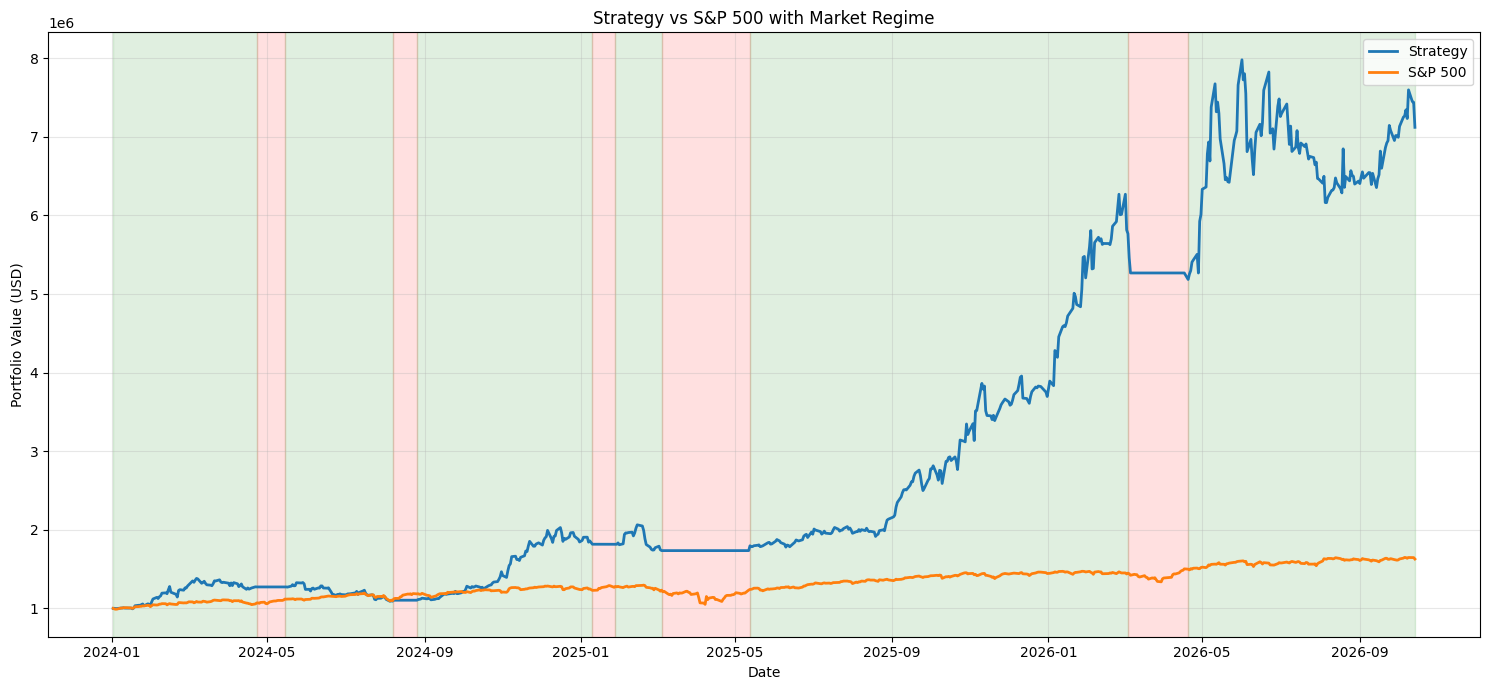

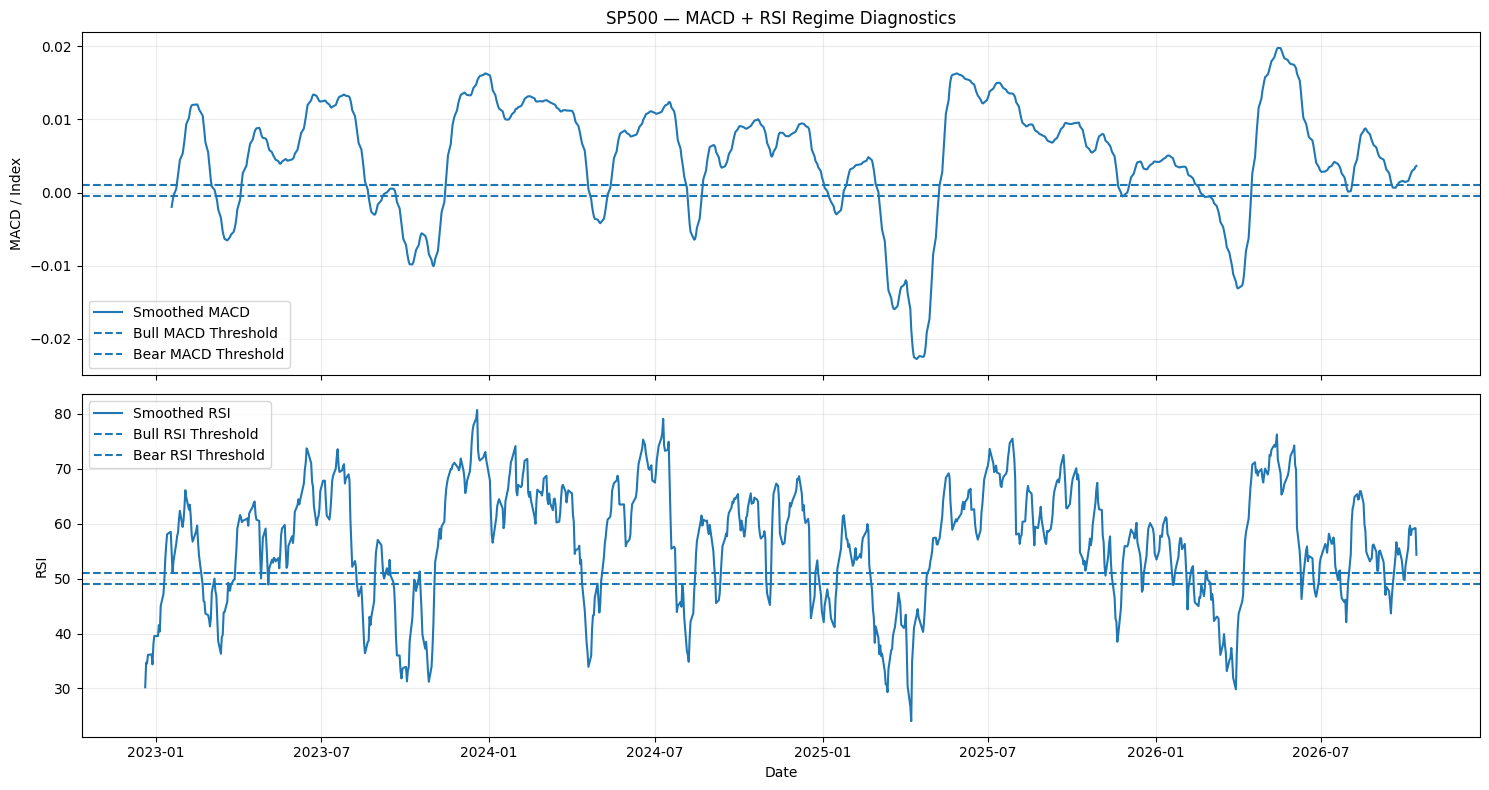

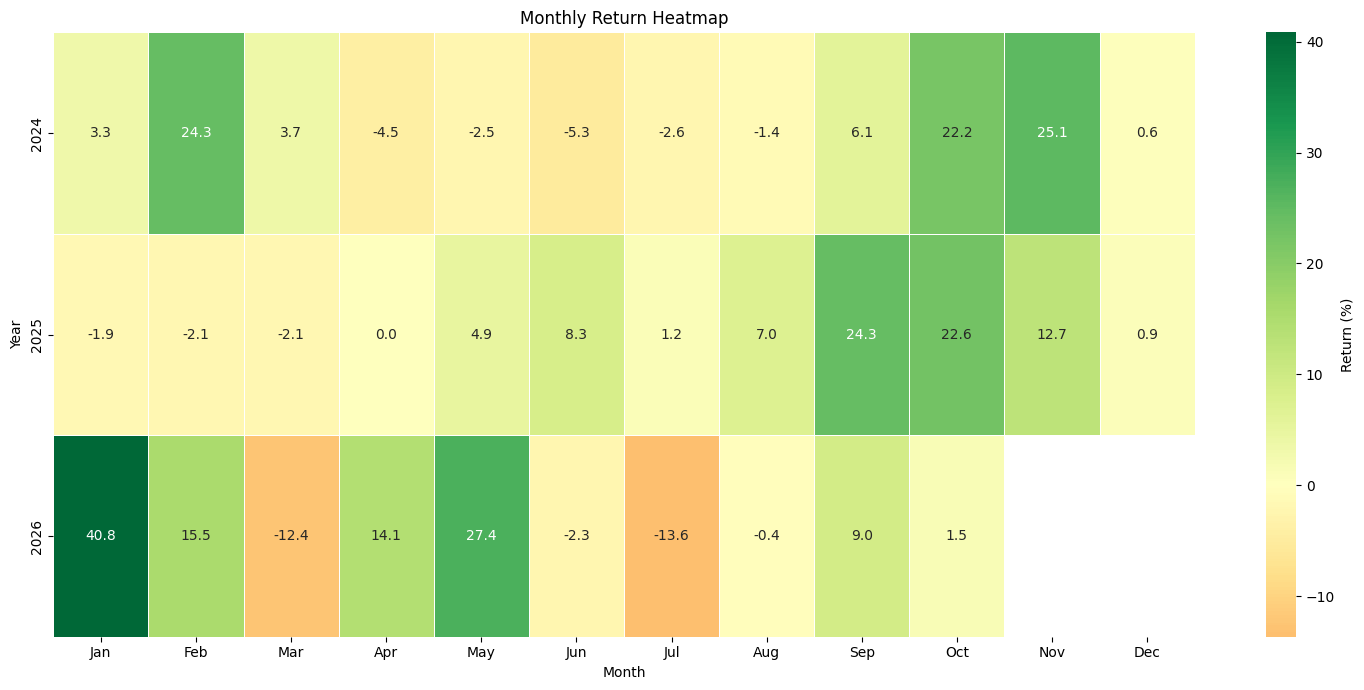

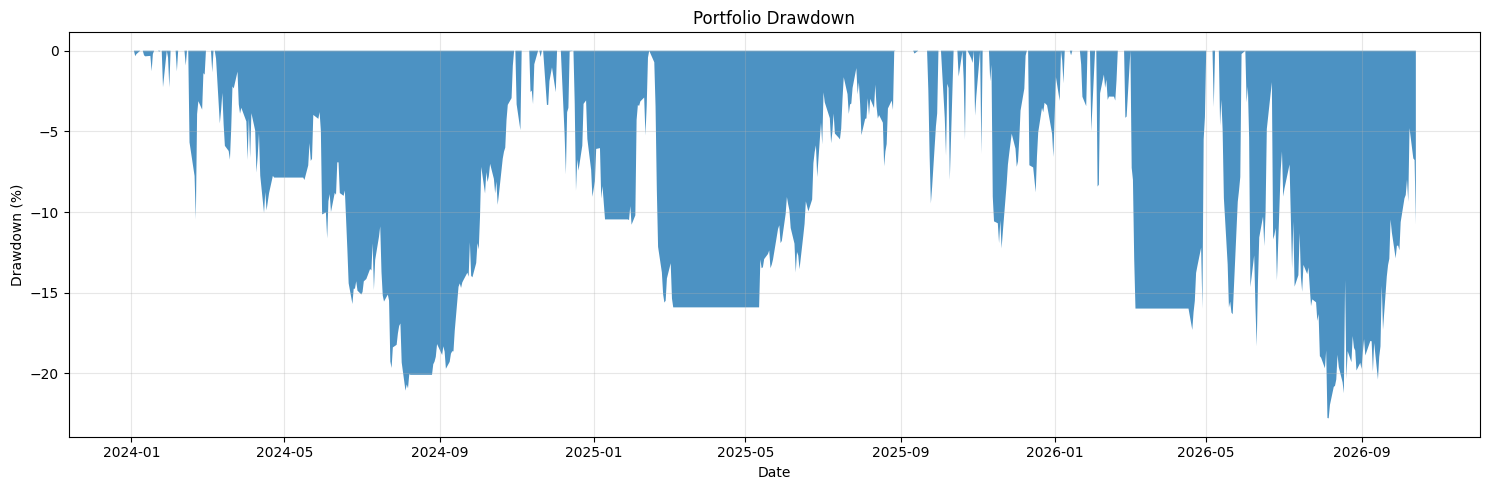


SAVING BACKTEST FILES
Output directory:
d:\projects\trading app\backtest_output

Trade log saved:
d:\projects\trading app\backtest_output\SP500_trade_log.csv

Top 5 stocks by trade frequency saved:
d:\projects\trading app\backtest_output\SP500_top5_trade_frequency.csv

TOP 5 STOCKS BY TRADE FREQUENCY
Ticker  TradeFrequency
    BE              41
  HOOD              41
  PLTR              40
   APP              39
   WDC              38

Strategy curve saved:
d:\projects\trading app\backtest_output\SP500_strategy_curve.csv
Benchmark curve saved:
d:\projects\trading app\backtest_output\SP500_benchmark_curve.csv
Monthly returns saved:
d:\projects\trading app\backtest_output\SP500_monthly_returns.csv
Backtest results saved:
d:\projects\trading app\backtest_output\SP500_backtest_results.csv
Regime data saved:
d:\projects\trading app\backtest_output\SP500_regime.csv

CSV FILES SAVED SUCCESSFULLY
Total trade records : 1391
Output directory    : d:\projects\trading app\backtest_output

Backte

In [20]:
# ==========================================================
# RUN BACKTEST FROM SAVED CSV DATA
# ==========================================================

UNIVERSE_CONFIG = {
    "NIFTY500": {
        "market": "INDIA",
        "currency": "INR",
        "benchmark_ticker": "^CRSLDX",
        "benchmark_name": "Nifty 500"
    },
    "SP500": {
        "market": "US",
        "currency": "USD",
        "benchmark_ticker": "^GSPC",
        "benchmark_name": "S&P 500"
    },
    "TOPIX500": {
        "market": "JAPAN",
        "currency": "JPY",
        "benchmark_ticker": "1306.T",
        "benchmark_name": "TOPIX"
    },
    "ASX300": {
        "market": "AUSTRALIA",
        "currency": "AUD",
        "benchmark_ticker": "^AXJO",
        "benchmark_name": "ASX 200"
    },
    "KOSPI500": {
        "market": "KOREA",
        "currency": "KRW",
        "benchmark_ticker": "^KS11",
        "benchmark_name": "KOSPI"
    }
}

if BACKTEST_UNIVERSE not in UNIVERSE_CONFIG:
    raise ValueError(
        f"Unknown universe: {BACKTEST_UNIVERSE}. "
        f"Choose from {list(UNIVERSE_CONFIG)}"
    )

cfg = UNIVERSE_CONFIG[BACKTEST_UNIVERSE]

result = run_strategy_backtest(
    universe_name=BACKTEST_UNIVERSE,

    # Open = signal + execution
    prices=prices,

    # Explicit OHLC for realistic stops
    open_prices=open_prices,
    high_prices=high_prices,
    low_prices=low_prices,
    close_prices=close_prices,

    # Saved benchmark — no web download here
    benchmark_ticker=cfg["benchmark_ticker"],
    benchmark_name=cfg["benchmark_name"],
    benchmark_prices=benchmark_prices,

    # Requested backtest period
    backtest_start_date=BACKTEST_START_DATE,
    backtest_end_date=BACKTEST_END_DATE,

    # Regime
    regime_index_prices=benchmark_prices,
    use_regime_filter=USE_REGIME_FILTER,

    # Binary regime filter: trade only during Bull.
# The regime itself is generated by the same canonical
# MarketRegime class + REGIME_CONFIG used in direct testing.
    allowed_regimes=("Bull",),

    # Stop loss
    use_stop_loss=USE_STOP_LOSS,
    stop_loss_type=STOP_LOSS_TYPE,
    stop_loss_pct=STOP_LOSS_PCT,

    # Rebalance
    rebalance_frequency=REBALANCE_FREQUENCY,

    # IBKR charges
    use_charges=USE_CHARGES,
    market=cfg["market"],
    currency=cfg["currency"],

    # Portfolio
    initial_capital=INITIAL_CAPITAL,

    # Output
    show_plots=True,
    save_csv=True
)

print("\nBacktest completed.")
